# Cancelación de reservas de hotel — EDA, modelo predictivo y verificación

## Pregunta de negocio
> **¿Qué características de la reserva (hotel, estancia, anticipación), del cliente (composición, historial, origen), del canal (segmento, distribución, agencia) y de las condiciones (depósito, tarifa, peticiones) están asociadas con la cancelación de una reserva y cuáles tienen mayor capacidad de predecirla?**

## De dónde venimos
Dataset público *Hotel Booking Demand* (Antonio, Almeida & Nunes, 2019): 119.390 reservas de dos hoteles de Portugal con llegada prevista entre julio de 2015 y agosto de 2017. El perfilado previo y las decisiones de contexto están en `docs/contexto_dataset.md`; el documento de traspaso en `docs/contexto_proyecto.md`. Este notebook sigue un flujo por etapas (perfilado → limpieza → EDA → modelado → verificación), cada una con sus decisiones documentadas.

## Qué hacemos en este notebook
0. **Entendimiento del problema**: qué se resuelve, tipo de problema, alcance y entregables.
1. **Análisis inicial**: carga, grano de la tabla, tipos, nulos, duplicados, valores sospechosos, validación del target.
2. **Limpieza**: duplicados, categorías, nulos sin regla única, inválidos, tipos, validación final y CSV limpio.
3. **Variables y target**: variables derivadas, correlaciones, definición formal del target y variables prohibidas.
4. **EDA**: indicadores globales, distribuciones, una sección por dimensión de negocio (tres métricas), evolución temporal e investigación del hallazgo principal.
5. **Conclusiones del EDA** y pregunta que deja para el modelo.
6. **Modelado**: target, prevención de fuga, split, preprocesamiento en cuatro etapas, comparación de modelos con validación cruzada, test único, umbral de negocio, interpretación y respuesta a la pregunta.
7. **Verificación**: tres caras de la importancia, leakage (cinco causas, tres métodos), drift (PSI, adversarial, partición temporal), tuning con Optuna y SHAP.
8. **Qué debe reportarse** al finalizar la ejecución.

Regla de lectura: cada bloque de código va precedido de *qué se hace y por qué* y seguido de una **Interpretación** o **Decisión**. Todo el lenguaje es de asociación, no de causalidad.

# 0. Entendimiento del problema

## 0.1 Qué se busca resolver
Los dos hoteles pierden ingresos cuando una reserva se cancela o el cliente no se presenta: la habitación queda vacía o se revende tarde y más barata. Hoy la cancelación se conoce cuando ocurre. Queremos **anticiparla al momento de la reserva** para que revenue management pueda actuar: confirmar activamente, pedir depósito, ajustar el overbooking o priorizar el contacto con las reservas de mayor riesgo. El objetivo operativo es **identificar los clientes/reservas con más posibilidades de cancelar**.

## 0.2 Tipo de problema
Aprendizaje **supervisado** de **clasificación binaria**: la variable objetivo es `is_canceled` (1 = cancelada o no-show, 0 = el cliente llegó). El resultado útil no es solo la etiqueta sino la **probabilidad** de cancelación, que permite ordenar las reservas por riesgo y elegir un umbral de negocio. Como el dato cubre tres años, también es un problema con **componente temporal** (hay que comprobar si lo aprendido en 2015–2016 sirve en 2017).

## 0.3 Alcance de la solución
| Dentro del alcance | Fuera del alcance |
|---|---|
| Entender qué características de la reserva, el cliente, el canal y las condiciones están asociadas con la cancelación (EDA con interpretación de negocio) | Explicar *causas* de la cancelación (no hay diseño causal; el lenguaje es de asociación) |
| Preparar los datos: duplicados, nulos, errores, atípicos, variables derivadas, con cada decisión documentada | Enriquecer con datos externos (clima, eventos, precios de competidores) |
| Construir, comparar y justificar un modelo predictivo con validación cruzada y una única evaluación en test | Optimizar el umbral con costos reales de negocio (se proponen tres umbrales; la decisión es de revenue) |
| Verificar fuga de información, drift temporal e interpretar el modelo (importancias, SHAP) | Despliegue del modelo (se guarda el artefacto entrenado; el servicio con FastAPI queda planteado como paso siguiente en `Despliegue_FastAPI.ipynb`, sin implementar aún) |
| Datos: `hotel_bookings.csv`, 119.390 reservas, llegadas jul-2015 a ago-2017 | Series de tiempo de ocupación o pronóstico de demanda agregada |

## 0.4 Entregables esperados
1. Este notebook ejecutado de principio a fin (exploración, preparación, modelo, verificación), con tablas y gráficos interpretados.
2. `data/hotel_bookings_limpio.csv`: dataset preparado, fuente única del modelado.
3. `docs/contexto_dataset.md` (qué significa cada variable, target, variables prohibidas) y `docs/contexto_proyecto.md` (traspaso con todas las cifras y decisiones).
4. `models/modelo_cancelacion.joblib`: pipeline final entrenado, con su metadata, listo para puntuar reservas nuevas.
5. Presentación para la sustentación (20 min + 5 de preguntas) con guion y banco de preguntas.
6. Pendiente (a aplicar después de la clase de despliegue): servicio FastAPI que cargue el artefacto; planteado en `Despliegue_FastAPI.ipynb`.

## 0.5 Cómo se organiza el trabajo frente a las fases pedidas
| Fase pedida (≈ fase CRISP-DM) | Dónde está en este notebook |
|---|---|
| Entendimiento del problema (comprensión del negocio) | Sección 0 y pregunta de negocio en la cabecera |
| Exploración de los datos (comprensión de los datos: variables, estadísticos, relaciones, tablas y visualizaciones interpretadas) | Sección 1 (perfilado: tipos, nulos, duplicados, estadísticos) y sección 4 (EDA por dimensiones de negocio, correlaciones, evolución temporal, hallazgo principal) |
| Preparación de los datos (nulos, errores, atípicos, transformaciones) | Secciones 2 (limpieza con tabla de decisiones) y 3 (variables derivadas, target, variables prohibidas) |
| Solución final: modelo, justificación, métricas, interpretación (modelado y evaluación) | Secciones 6 (modelado) y 7 (verificación, tuning, SHAP); resumen en sección 8 |
| Despliegue y mantenimiento | Artefacto en `models/` (7.5), drift y reentrenamiento (7.4); servicio pendiente en `Despliegue_FastAPI.ipynb` |

La tabla completa "concepto de la materia → dónde se aplica" está en `docs/base_conocimiento_materia.md`.

Nota sobre el orden: el perfilado (sección 1) explora los datos *crudos* para decidir la limpieza; el EDA de negocio (sección 4) se hace sobre los datos *ya preparados* para que las cifras que se presentan sean las definitivas.

## 0.6 Traducción CRISP-DM del objetivo y KPIs
Siguiendo la metodología vista en clase (sesión 2), el objetivo se traduce en tres niveles y se fijan los indicadores con los que se juzgará el resultado.

| Nivel | Formulación |
|---|---|
| **Objetivo de negocio** | Reducir el ingreso perdido por cancelaciones y no-shows, actuando antes de la fecha de llegada sobre las reservas de mayor riesgo |
| **Objetivo de ciencia de datos** | Modelo de clasificación que asigne a cada reserva, al momento de crearla, una probabilidad de cancelación, y que explique qué características están asociadas con ella |
| **Criterio de éxito** | Ordenar bien el riesgo (ROC-AUC claramente superior al azar y a un modelo lineal simple) y que el 10 % de reservas de mayor riesgo concentre una tasa real de cancelación al menos 2,5 veces la global; sin fuga de información y con desempeño verificado fuera del periodo de entrenamiento |

| KPI | Tipo | Dónde se mide | Para qué sirve |
|---|---|---|---|
| Tasa de cancelación (canceladas / reservas) | negocio | 4.1 y por dimensión en 4.5–4.9 | Línea base y seguimiento por canal, mercado y periodo |
| Ingreso en riesgo (Σ adr × noches de las canceladas) | negocio | 4.1 | Traduce la cancelación a euros; prioriza dónde actuar |
| ROC-AUC y PR-AUC en test | modelo | 6.7 y 7.5 | Calidad del ranking de riesgo (PR-AUC exigente con desbalance) |
| Recall y precision al umbral de negocio | modelo / operación | 6.8 y 7.5 | Cuántas cancelaciones se anticipan y cuántas alertas sobran |
| Lift del decil de mayor riesgo y % de cancelaciones en los 2 primeros deciles | operación | 6.8.1 y 7.5 | Cuánto rinde revisar solo las reservas de mayor puntuación |
| AUC en partición temporal (entrenar 2015–16, probar 2017) | mantenimiento | 7.4 | Detecta drift y marca cuándo reentrenar |

Cada KPI responde a las preguntas de validación del material: mide lo que se quiere (no es demasiado general), se puede calcular con los datos disponibles, tiene periodicidad clara (por mes de llegada) y liga la métrica del modelo con la decisión del negocio.

In [1]:
# Librerías y configuración (local o Colab). Si falta optuna/shap: !pip install optuna shap -q
import warnings, time, sys
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
RANDOM_STATE = 42

# Ruta del dato: carpeta del proyecto (local) o /content (Colab)
RUTA = Path("hotel_bookings.csv") if Path("hotel_bookings.csv").exists() else Path("/content/hotel_bookings.csv")
Path("data").mkdir(exist_ok=True); Path("docs").mkdir(exist_ok=True); Path("models").mkdir(exist_ok=True)
print("Dato:", RUTA.resolve())

Dato: C:\Proyectos\python\Especializacion\hotel_bookings.csv


# 1. Análisis inicial (perfilado)

## 1.1 Carga y primera vista
Cargamos el CSV crudo y miramos dimensiones, primeras filas y una muestra aleatoria para entender qué contiene cada columna antes de decidir nada.

In [2]:
df = pd.read_csv(RUTA)
print("Dimensiones:", df.shape)
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))

Dimensiones: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
30946,Resort Hotel,0,203,2016,December,49,2,2,5,2,0.0,0,BB,GBR,Direct,Direct,0,0,0,F,F,4,No Deposit,250.0,NaN,0,Transient,66.8,0,0,Check-Out,2016-12-09
40207,City Hotel,1,82,2015,July,29,16,0,3,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,76.5,0,0,Canceled,2015-07-16
103708,City Hotel,0,25,2016,December,53,27,0,3,3,0.0,0,BB,BRA,Offline TA/TO,TA/TO,0,0,0,A,K,2,No Deposit,220.0,NaN,0,Transient-Party,60.0,0,1,Check-Out,2016-12-30
85144,City Hotel,0,1,2016,March,11,9,0,1,1,0.0,0,BB,SWE,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient-Party,95.0,0,0,Check-Out,2016-03-10
109991,City Hotel,0,70,2017,April,16,16,2,2,2,0.0,0,SC,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,108.0,0,0,Check-Out,2017-04-20


**Interpretación.** 119.390 filas × 32 columnas. Cada fila es una **reserva** (una habitación con fecha de llegada) en uno de dos hoteles; no hay identificador de reserva ni de cliente. `agent` y `company` llegan como números con nulos (`NULL` en el archivo) y `reservation_status_date` como texto.

## 1.2 ¿Qué representa una fila? Duplicados exactos
Sin un ID no podemos contar reservas únicas; lo que sí podemos medir es cuántas filas son **completamente idénticas** y dónde se concentran, porque esa decisión cambia el tamaño del dataset y la prevalencia del target.

In [3]:
n_dup = df.duplicated().sum()
dup_mask = df.duplicated(keep=False)
print(f"Filas duplicadas exactas: {n_dup:,} ({n_dup/len(df):.1%}); filas únicas si se eliminan: {len(df)-n_dup:,}")
print(f"Tasa de cancelación: cruda {df.is_canceled.mean():.1%} | filas implicadas en duplicados {df[dup_mask].is_canceled.mean():.1%} | filas sin duplicado {df[~dup_mask].is_canceled.mean():.1%}")
conc = pd.DataFrame({
    "por segmento": df.groupby("market_segment").apply(lambda g: g.duplicated().sum(), include_groups=False),
}).sort_values("por segmento", ascending=False)
conc2 = df.groupby("deposit_type").apply(lambda g: g.duplicated().sum(), include_groups=False).rename("duplicados")
display(conc.T); display(pd.concat([conc2, df.deposit_type.value_counts().rename("filas")], axis=1))

Filas duplicadas exactas: 31,994 (26.8%); filas únicas si se eliminan: 87,396
Tasa de cancelación: cruda 37.0% | filas implicadas en duplicados 58.4% | filas sin duplicado 26.2%


market_segment,Groups,Offline TA/TO,Online TA,Corporate,Direct,Complementary,Aviation,Undefined
por segmento,14869,10330,4859,1083,802,41,10,0


,duplicados,filas
deposit_type,,
No Deposit,18390,104641
Non Refund,13549,14587
Refundable,55,162


**Interpretación.** 31.994 filas (26,8 %) son copias exactas de otra. No están repartidas al azar: 14.869 vienen de *Groups* y 10.330 de *Offline TA/TO*, y 13.549 de las 14.587 filas con depósito *Non Refund* son duplicados. Las filas duplicadas se cancelan en 58,4 % de los casos frente a 26,2 % en las no duplicadas. Esto parece **bloques de reservas** (un operador reserva n habitaciones idénticas el mismo día), pero sin ID de reserva no podemos comprobarlo.

### Decisión
Eliminamos los duplicados exactos (119.390 → 87.396). Razones: (1) sin identificador no hay forma de validar que sean reservas distintas; (2) si se conservan, filas idénticas caerían en train y en test y el modelo mediría memorización (fuga por duplicados, causa 3 del checklist de leakage). Costo asumido: los bloques de grupos quedan subrepresentados y la prevalencia baja de 37,0 % a 27,5 %. En la sección 7.3 cuantificamos cuánto inflan los duplicados las métricas. Alternativa descartada: conservarlos y partir por "grupo de filas idénticas" (más complejo y sigue sin resolver si son reservas reales).

## 1.3 Tipos y clasificación de variables
Clasificamos cada columna por tipo estadístico, rol y **dimensión de negocio**. Las dimensiones son el eje de interpretación de todo el proyecto.

| Dimensión | Columnas |
|---|---|
| **Hotel y estancia** | hotel, stays_in_weekend_nights, stays_in_week_nights, reserved_room_type, meal |
| **Cliente** | adults, children, babies, is_repeated_guest, previous_cancellations, previous_bookings_not_canceled, customer_type, country |
| **Canal** | market_segment, distribution_channel, agent, company |
| **Tiempo y anticipación** | lead_time, days_in_waiting_list, arrival_date_year / month / week_number / day_of_month |
| **Condiciones de la reserva** | deposit_type, adr, booking_changes, total_of_special_requests, required_car_parking_spaces |
| **Resultado** | is_canceled (**target**), reservation_status y reservation_status_date (**fuga**), assigned_room_type (**post-evento**) |

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

## 1.4 Estadísticos descriptivos
`describe` de numéricas y categóricas para detectar rangos imposibles y categorías dominantes.

In [5]:
display(df.describe().T.round(2))
display(df.describe(include=["object", "str"]).T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.37,0.48,0.00,0.00,0.00,1.0,1.0
lead_time,119390.0,104.01,106.86,0.00,18.00,69.00,160.0,737.0
arrival_date_year,119390.0,2016.16,0.71,2015.00,2016.00,2016.00,2017.0,2017.0
arrival_date_week_number,119390.0,27.17,13.61,1.00,16.00,28.00,38.0,53.0
arrival_date_day_of_month,119390.0,15.80,8.78,1.00,8.00,16.00,23.0,31.0
stays_in_weekend_nights,119390.0,0.93,1.00,0.00,0.00,1.00,2.0,19.0
stays_in_week_nights,119390.0,2.50,1.91,0.00,1.00,2.00,3.0,50.0
adults,119390.0,1.86,0.58,0.00,2.00,2.00,2.0,55.0
children,119386.0,0.10,0.40,0.00,0.00,0.00,0.0,10.0
babies,119390.0,0.01,0.10,0.00,0.00,0.00,0.0,10.0


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


**Interpretación.** `adr` tiene mínimo −6,38 y máximo 5.400 (la mediana es 94,6): dos valores a revisar. `adults` llega a 55 y `babies` a 10 en filas aisladas. `lead_time` va de 0 a 737 días con mediana 69. `company` es nula en el 94 % de las filas.

## 1.5 Nulos por columna
Separamos los nulos **esperables con significado** (sin agencia, sin empresa) de los **errores** (país desconocido, niños sin registrar).

In [6]:
nulos = df.isna().sum(); nulos = nulos[nulos > 0]
display(pd.DataFrame({"nulos": nulos, "%": (nulos / len(df) * 100).round(2)}).sort_values("nulos", ascending=False))

,nulos,%
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


**Interpretación.** Solo cuatro columnas tienen nulos: `company` 94,3 % y `agent` 13,7 % son *esperables* (la reserva no pasó por empresa o por agencia y se convertirán en una constante con significado más una bandera); `country` 0,41 % (488) y `children` (4) son errores de registro.

## 1.6 Categóricas: frecuencias y variantes
Buscamos variantes de escritura y categorías comodín (`Undefined`).

In [7]:
cat_cols = ["hotel", "meal", "market_segment", "distribution_channel", "reserved_room_type", "assigned_room_type",
            "deposit_type", "customer_type", "reservation_status"]
for c in cat_cols:
    print(f"\n{c}:", df[c].value_counts().to_dict())
print("\nPaíses distintos:", df.country.nunique(), "| agencias:", df.agent.nunique(), "| empresas:", df.company.nunique())


hotel: {'City Hotel': 79330, 'Resort Hotel': 40060}

meal: {'BB': 92310, 'HB': 14463, 'SC': 10650, 'Undefined': 1169, 'FB': 798}

market_segment: {'Online TA': 56477, 'Offline TA/TO': 24219, 'Groups': 19811, 'Direct': 12606, 'Corporate': 5295, 'Complementary': 743, 'Aviation': 237, 'Undefined': 2}

distribution_channel: {'TA/TO': 97870, 'Direct': 14645, 'Corporate': 6677, 'GDS': 193, 'Undefined': 5}

reserved_room_type: {'A': 85994, 'D': 19201, 'E': 6535, 'F': 2897, 'G': 2094, 'B': 1118, 'C': 932, 'H': 601, 'P': 12, 'L': 6}

assigned_room_type: {'A': 74053, 'D': 25322, 'E': 7806, 'F': 3751, 'G': 2553, 'C': 2375, 'B': 2163, 'H': 712, 'I': 363, 'K': 279, 'P': 12, 'L': 1}

deposit_type: {'No Deposit': 104641, 'Non Refund': 14587, 'Refundable': 162}

customer_type: {'Transient': 89613, 'Transient-Party': 25124, 'Contract': 4076, 'Group': 577}

reservation_status: {'Check-Out': 75166, 'Canceled': 43017, 'No-Show': 1207}

Países distintos: 177 | agencias: 333 | empresas: 352


**Interpretación.** No hay variantes de mayúsculas o espacios. Sí hay `Undefined` en `meal` (1.169 filas; según el diccionario original equivale a *SC*, sin paquete de comidas), en `market_segment` (2) y en `distribution_channel` (5). `country`, `agent` y `company` tienen alta cardinalidad (177, 333 y 352 valores) y necesitarán agrupar categorías raras en el modelo.

## 1.7 Numéricas sospechosas
Revisamos `adr` (tarifa), reservas sin huéspedes y estancias de cero noches.

In [8]:
huespedes = df.adults + df.children.fillna(0) + df.babies
noches = df.stays_in_weekend_nights + df.stays_in_week_nights
print(f"adr < 0: {(df.adr < 0).sum()} | adr == 0: {(df.adr == 0).sum():,} | adr > 1000: {(df.adr > 1000).sum()} | adr > 500: {(df.adr > 500).sum()}")
display(df.loc[(df.adr < 0) | (df.adr > 500), ["hotel", "adr", "market_segment", "arrival_date_year", "is_canceled"]])
print(f"\nReservas con 0 huéspedes: {(huespedes == 0).sum()} (tasa de cancelación {df[huespedes == 0].is_canceled.mean():.1%}, adr mediano {df[huespedes == 0].adr.median():.0f})")
print(f"Estancias de 0 noches: {(noches == 0).sum()} (tasa de cancelación {df[noches == 0].is_canceled.mean():.1%})")
print("adr == 0 por segmento:", df[df.adr == 0].market_segment.value_counts().head(4).to_dict())

adr < 0: 1 | adr == 0: 1,959 | adr > 1000: 1 | adr > 500: 3


,hotel,adr,market_segment,arrival_date_year,is_canceled
14969,Resort Hotel,-6.38,Groups,2017,0
15083,Resort Hotel,508.00,Corporate,2015,0
48515,City Hotel,5400.00,Offline TA/TO,2016,1
111403,City Hotel,510.00,Offline TA/TO,2017,0



Reservas con 0 huéspedes: 180 (tasa de cancelación 13.9%, adr mediano 0)
Estancias de 0 noches: 715 (tasa de cancelación 4.9%)
adr == 0 por segmento: {'Complementary': 680, 'Online TA': 367, 'Offline TA/TO': 332, 'Groups': 252}


**Interpretación.** `adr` = −6,38 (1 fila) y 5.400 (1 fila, diez veces el siguiente máximo de 510) son errores evidentes → se pasarán a nulo. `adr` = 0 en 1.959 filas es válido en su mayoría (680 son *Complementary*: estancias de cortesía). Las 180 reservas con 0 huéspedes no son reservas utilizables (adr casi siempre 0) → se eliminan. Las 715 estancias de 0 noches son uso de día (se cancelan solo 4,9 %) → se conservan.

## 1.8 Validación del target contra `reservation_status`
Si `is_canceled` se deriva de `reservation_status`, esta última es **fuga total** y no puede ser predictor.

In [9]:
display(pd.crosstab(df.reservation_status, df.is_canceled))
assert ((df.reservation_status != "Check-Out").astype(int) == df.is_canceled).all()
print("is_canceled == 1  <=>  reservation_status in {Canceled, No-Show}: confirmado en el 100 % de las filas")

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


is_canceled == 1  <=>  reservation_status in {Canceled, No-Show}: confirmado en el 100 % de las filas


**Interpretación.** La correspondencia es exacta: 43.017 *Canceled* + 1.207 *No-Show* = 44.224 canceladas; 75.166 *Check-Out* = no canceladas. `reservation_status` y su fecha quedan prohibidas como predictores. Lo mismo ocurre con `assigned_room_type`: se asigna al check-in, así que casi solo las reservas que llegaron cambian de habitación (ver 4.11).

## 1.9 Rango temporal
Construimos la fecha de llegada y revisamos cobertura por año: los años incompletos obligan a comparar mes a mes.

In [10]:
fecha = pd.to_datetime(df.arrival_date_year.astype(str) + "-" + df.arrival_date_month + "-" + df.arrival_date_day_of_month.astype(str), format="%Y-%B-%d")
print("Llegadas desde", fecha.min().date(), "hasta", fecha.max().date())
display(df.groupby("arrival_date_year").agg(reservas=("is_canceled", "size"), meses=("arrival_date_month", "nunique")))

Llegadas desde 2015-07-01 hasta 2017-08-31


,reservas,meses
arrival_date_year,,
2015,21996,6
2016,56707,12
2017,40687,8


**Interpretación.** 2015 cubre julio–diciembre y 2017 enero–agosto; solo 2016 está completo. Cualquier comparación anual se hará por mes dentro de cada año. La variable temporal habilita evolución en el tiempo, partición temporal y análisis de drift (sección 7.4).

### Decisiones pendientes para la limpieza
1. Eliminar duplicados exactos y reservas con 0 huéspedes.
2. `adr` −6,38 y 5.400 → nulo (se conservan como nulo; el pipeline de modelado imputa con la mediana de train).
3. `children` → 0 (moda); `country` → "Unknown"; `agent`/`company` → constante "SinAgencia"/"SinEmpresa" + banderas.
4. `meal` Undefined → SC. `market_segment`/`distribution_channel` Undefined se conservan (7 filas).
5. Construir `arrival_date` y derivadas; `reservation_status_date` a fecha solo para verificación.

# 2. Limpieza y calidad de datos

Trabajamos sobre una copia e imprimimos el conteo de filas antes y después de cada paso que las cambie.

## 2.0 Duplicados exactos

In [11]:
df_clean = df.copy()
antes = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Duplicados exactos: {antes:,} → {len(df_clean):,} filas (−{antes - len(df_clean):,})")

Duplicados exactos: 119,390 → 87,396 filas (−31,994)


## 2.1 Estandarización de categorías
Recorte de espacios y diccionario de reemplazo explícito (`Undefined` → `SC` en `meal`, según el diccionario del dataset).

In [12]:
for c in ["hotel", "meal", "country", "market_segment", "distribution_channel", "reserved_room_type",
          "assigned_room_type", "deposit_type", "customer_type", "reservation_status", "arrival_date_month"]:
    df_clean[c] = df_clean[c].str.strip()
df_clean["meal"] = df_clean["meal"].replace({"Undefined": "SC"})
print(df_clean.meal.value_counts().to_dict())

{'BB': 67978, 'SC': 9973, 'HB': 9085, 'FB': 360}


## 2.2 Nulos: sin regla única
Cada columna con nulos recibe el tratamiento que corresponde a su significado.

In [13]:
n0 = df_clean.isna().sum()
df_clean["children"] = df_clean["children"].fillna(0).astype(int)              # 4 nulos → moda (0)
df_clean["country"] = df_clean["country"].fillna("Unknown")                     # error → categoría explícita
df_clean["has_agent"] = df_clean["agent"].notna().astype(int)                   # bandera con significado
df_clean["has_company"] = df_clean["company"].notna().astype(int)
df_clean["agent"] = df_clean["agent"].fillna(0).astype(int).astype(str).replace({"0": "SinAgencia"})
df_clean["company"] = df_clean["company"].fillna(0).astype(int).astype(str).replace({"0": "SinEmpresa"})
print("Nulos tratados:", n0[n0 > 0].to_dict())
print("Moda usada en children: 0 | country desconocido:", (df_clean.country == "Unknown").sum(),
      "| sin agencia:", (df_clean.has_agent == 0).sum(), "| sin empresa:", (df_clean.has_company == 0).sum())

Nulos tratados: {'children': 4, 'country': 452, 'agent': 12193, 'company': 82137}
Moda usada en children: 0 | country desconocido: 452 | sin agencia: 12193 | sin empresa: 82137


**Decisión.** `agent` y `company` nulos no son errores: significan *reserva sin intermediario / sin empresa*. Por eso reciben una constante explícita y una bandera, en lugar de imputación. `children` (4 filas) toma la moda y `country` (488) una categoría "Unknown" que el modelo puede usar.

## 2.3 Valores inválidos
`adr` fuera de rango → nulo (no se borra la fila); reservas sin huéspedes → se eliminan porque no pueden corregirse.

In [14]:
inv_adr = ((df_clean.adr < 0) | (df_clean.adr > 1000)).sum()
df_clean.loc[(df_clean.adr < 0) | (df_clean.adr > 1000), "adr"] = np.nan
huespedes = df_clean.adults + df_clean.children + df_clean.babies
antes = len(df_clean)
df_clean = df_clean[huespedes > 0].reset_index(drop=True)
print(f"adr inválidos → NaN: {inv_adr} | reservas con 0 huéspedes eliminadas: {antes - len(df_clean)} → {len(df_clean):,} filas")
print(f"adr: mediana {df_clean.adr.median():.2f}, media {df_clean.adr.mean():.2f}, máximo {df_clean.adr.max():.0f}; nulos restantes {df_clean.adr.isna().sum()}")

adr inválidos → NaN: 2 | reservas con 0 huéspedes eliminadas: 166 → 87,230 filas
adr: mediana 98.20, media 106.46, máximo 510; nulos restantes 2


**Decisión.** Los dos `adr` inválidos se conservan como nulo (0,002 % de las filas): la mediana del EDA no cambia y en modelado los imputa el pipeline con datos de train (imputar aquí con todo el dataset sería procesar antes de partir). Los outliers altos de `adr` (hasta 510) **no se eliminan**: no hay evidencia de error; en los histogramas se recorta el eje al percentil 95 solo para visualizar.

## 2.4 Tipos y variables derivadas de fecha

In [15]:
df_clean["arrival_date"] = pd.to_datetime(df_clean.arrival_date_year.astype(str) + "-" + df_clean.arrival_date_month + "-" + df_clean.arrival_date_day_of_month.astype(str), format="%Y-%B-%d")
df_clean["reservation_status_date"] = pd.to_datetime(df_clean.reservation_status_date, errors="coerce")
df_clean["arrival_month_num"] = df_clean.arrival_date.dt.month
df_clean["arrival_quarter"] = df_clean.arrival_date.dt.quarter
df_clean["arrival_dow"] = df_clean.arrival_date.dt.day_name()
df_clean["year_month"] = df_clean.arrival_date.dt.to_period("M").astype(str)
print("NaT en fechas:", df_clean.arrival_date.isna().sum(), df_clean.reservation_status_date.isna().sum())
print(df_clean[["arrival_date", "arrival_month_num", "arrival_quarter", "arrival_dow", "year_month"]].head(3))

NaT en fechas:

 0 0
  arrival_date  arrival_month_num  arrival_quarter arrival_dow year_month
0   2015-07-01                  7                3   Wednesday    2015-07
1   2015-07-01                  7                3   Wednesday    2015-07
2   2015-07-01                  7                3   Wednesday    2015-07


## 2.5 Dataset auxiliar
No aplica: ninguna columna conserva nulos relevantes (solo 2 en `adr`).

## 2.6 Validación final y CSV limpio

In [16]:
assert df_clean.duplicated().sum() == 0
assert (df_clean.adults + df_clean.children + df_clean.babies > 0).all()
assert df_clean.adr.dropna().between(0, 1000).all()
assert df_clean.isna().sum().drop("adr").sum() == 0
print("Dimensiones finales:", df_clean.shape)
print("Nulos restantes:", df_clean.isna().sum()[df_clean.isna().sum() > 0].to_dict())
print(f"Tasa de cancelación: {df_clean.is_canceled.mean():.2%}")
df_clean.to_csv("data/hotel_bookings_limpio.csv", index=False)
print("Guardado data/hotel_bookings_limpio.csv")

Dimensiones finales: (87230, 39)


Nulos restantes: {'adr': 2}
Tasa de cancelación: 27.52%


Guardado data/hotel_bookings_limpio.csv


## 2.7 Tabla de decisiones de limpieza

| Variable | Problema | Acción | Valor usado | Justificación |
|---|---|---|---|---|
| (todas) | 31.994 filas idénticas | `drop_duplicates` | 119.390 → 87.396 | sin ID de reserva no se puede validar que sean reservas distintas; evita fuga train/test |
| adults+children+babies | 180 reservas con 0 huéspedes (166 tras dedup) | eliminar filas | 87.396 → 87.230 | no es una reserva utilizable y no se puede corregir |
| adr | −6,38 y 5.400 | → NaN, se conserva nulo | 2 filas | error evidente; imputación dentro del pipeline con train |
| adr | 1.959 ceros, máximo 510 | conservar | — | cortesías válidas; sin evidencia de error en los altos |
| children | 4 nulos | moda | 0 | pocos nulos, variable discreta |
| country | 488 nulos | constante | "Unknown" | categoría que el modelo puede usar |
| agent / company | 13,7 % / 94,3 % nulos | constante + bandera | "SinAgencia" / "SinEmpresa", `has_agent`, `has_company` | nulo con significado: sin intermediario |
| meal | `Undefined` (1.169) | reemplazo explícito | "SC" | equivalencia del diccionario oficial |
| market_segment / distribution_channel | `Undefined` (2 / 5) | conservar | — | demasiado pocas filas; se agrupan como infrecuentes |
| stays 0 noches | 715 | conservar | — | uso de día; se cancelan 4,9 % |
| fechas | mes en texto, estado en texto | `to_datetime` | `arrival_date`, `reservation_status_date` | 0 NaT |

**Filas: 119.390 → 87.230.** Ninguna otra fila se eliminó: los valores inválidos se corrigieron o se dejaron como nulo.

# 3. Creación de variables, correlaciones y target

## 3.1 Variables derivadas con lectura de negocio
Solo creamos variables que un lector de negocio pueda interpretar.

| Variable | Cálculo | Lectura |
|---|---|---|
| `total_nights` | weekend + week nights | duración de la estancia |
| `total_guests` | adults + children + babies | tamaño del grupo |
| `ingreso_estimado` | adr × total_nights | valor de la reserva (€); su suma en canceladas = **ingreso en riesgo** |
| `room_changed` | reserved ≠ assigned | solo para verificar fuga (post-evento) |
| `lead_bin` | rangos de lead_time | 0–7, 8–30, 31–90, 91–180, >180 días |
| `es_PRT` | country == PRT | mercado doméstico vs. internacional |

In [17]:
df_eda = df_clean.copy()
df_eda["total_nights"] = df_eda.stays_in_weekend_nights + df_eda.stays_in_week_nights
df_eda["total_guests"] = df_eda.adults + df_eda.children + df_eda.babies
df_eda["ingreso_estimado"] = df_eda.adr * df_eda.total_nights
df_eda["room_changed"] = (df_eda.reserved_room_type != df_eda.assigned_room_type).astype(int)
df_eda["lead_bin"] = pd.cut(df_eda.lead_time, [-1, 7, 30, 90, 180, 800], labels=["0-7", "8-30", "31-90", "91-180", ">180"])
df_eda["es_PRT"] = np.where(df_eda.country == "PRT", "Portugal", "Otros países")
display(df_eda[["lead_time", "lead_bin", "total_nights", "total_guests", "adr", "ingreso_estimado", "room_changed", "es_PRT"]].head())

,lead_time,lead_bin,total_nights,total_guests,adr,ingreso_estimado,room_changed,es_PRT
0,342,>180,0,2,0.0,0.0,0,Portugal
1,737,>180,0,2,0.0,0.0,0,Portugal
2,7,0-7,1,1,75.0,75.0,1,Otros países
3,13,8-30,1,1,75.0,75.0,0,Otros países
4,14,8-30,2,2,98.0,196.0,0,Otros países


## 3.2 Correlación entre numéricas
La correlación de Pearson mide cuánto se mueven juntas dos variables numéricas, de −1 (sentido contrario) a +1 (mismo sentido); 0 significa que no hay relación lineal. Buscamos pares ≥ 0,9 (redundancia) y la relación de cada numérica con el target.

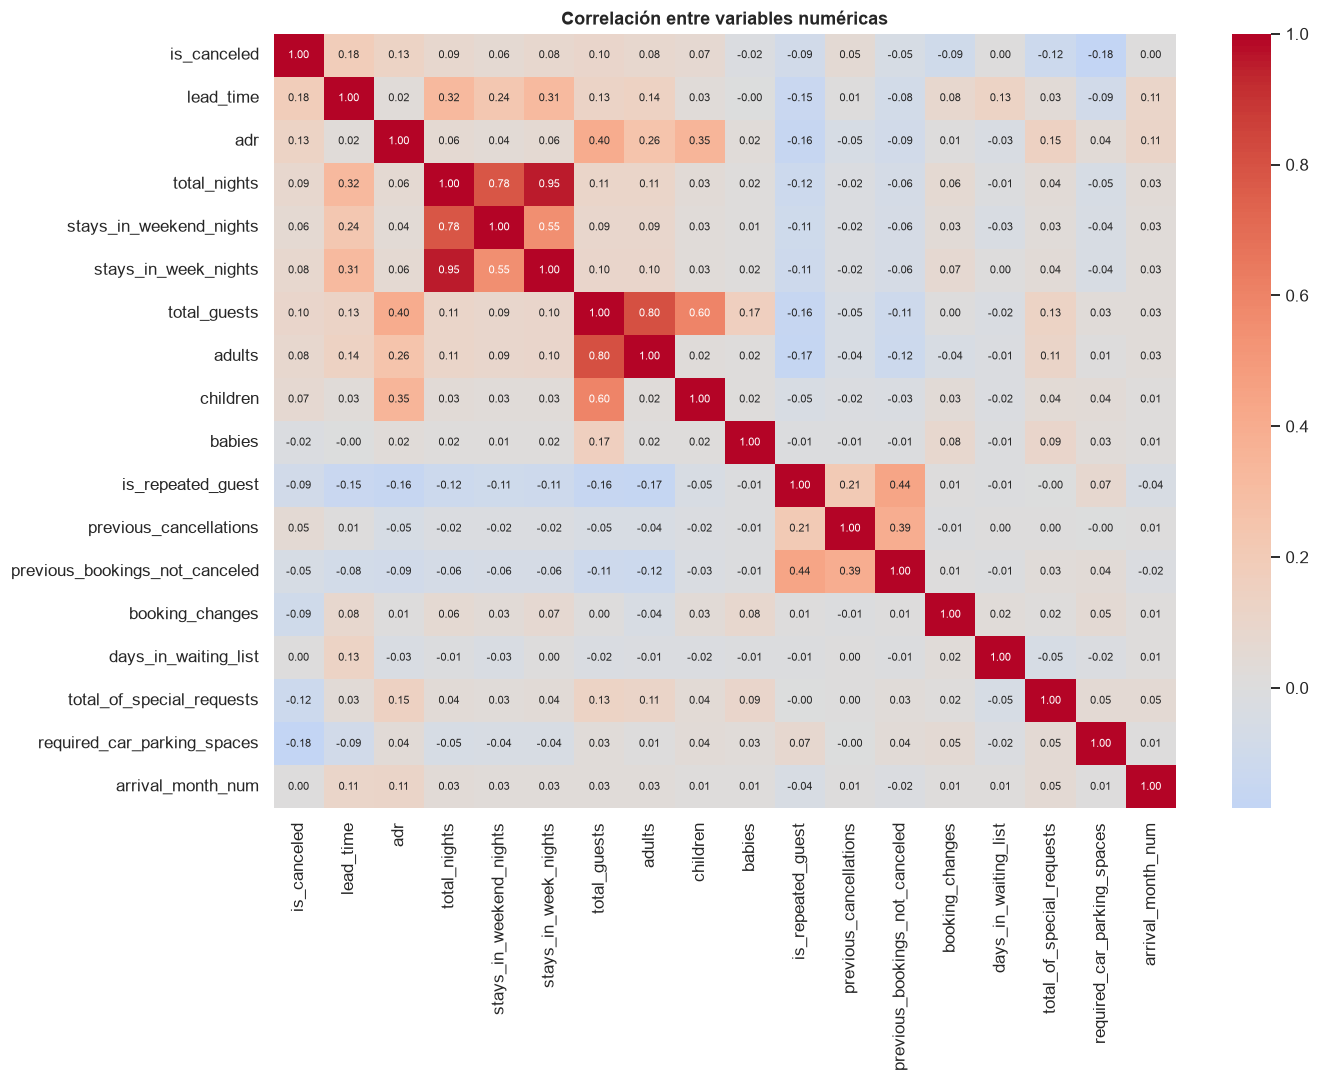

Pares con |r| ≥ 0,9: [('total_nights', 'stays_in_week_nights', np.float64(0.95))]


In [18]:
num_cols = ["is_canceled", "lead_time", "adr", "total_nights", "stays_in_weekend_nights", "stays_in_week_nights", "total_guests", "adults", "children",
            "babies", "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
            "days_in_waiting_list", "total_of_special_requests", "required_car_parking_spaces", "arrival_month_num"]
corr = df_eda[num_cols].corr()
plt.figure(figsize=(13, 10)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlación entre variables numéricas", fontweight="bold"); plt.tight_layout(); plt.show()
pares = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.9]
print("Pares con |r| ≥ 0,9:", pares if pares else "ninguno (los derivados total_* con sus componentes quedan en 0,6–0,9)")

**Interpretación.** No hay pares ≥ 0,9. Las únicas correlaciones altas son las esperadas entre `total_guests` y sus componentes (0,80 con `adults`) y entre `total_nights` y las noches entre semana; en modelado se usarán los componentes y no los totales. Ninguna numérica se correlaciona fuertemente con el target: el problema no es lineal ni de una sola variable.

## 3.3 Correlación de cada numérica con el target

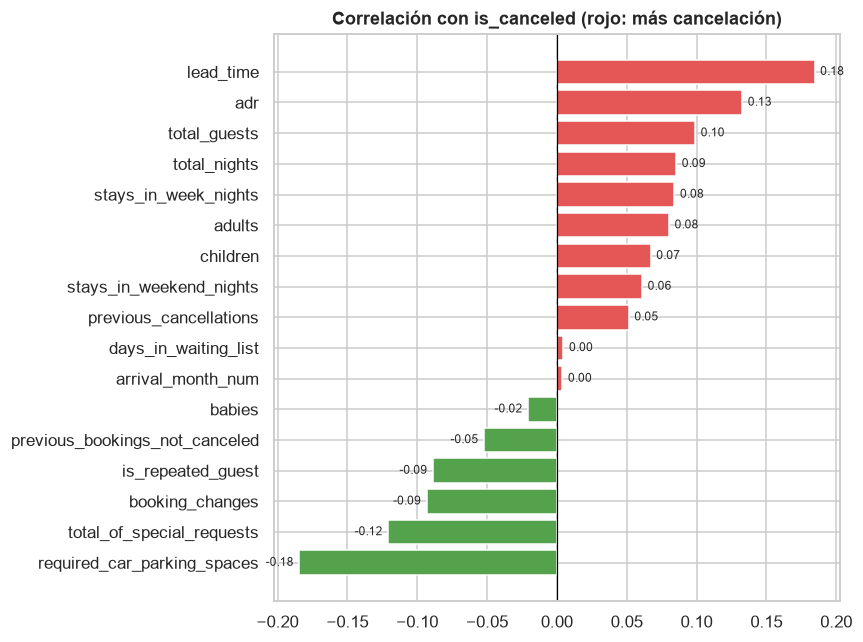

In [19]:
ct = corr["is_canceled"].drop("is_canceled").sort_values()
plt.figure(figsize=(8, 6)); colors = ["#E45756" if v > 0 else "#54A24B" for v in ct]
plt.barh(ct.index, ct.values, color=colors)
for i, v in enumerate(ct.values): plt.text(v + (0.004 if v > 0 else -0.004), i, f"{v:.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
plt.axvline(0, color="black", lw=0.8); plt.title("Correlación con is_canceled (rojo: más cancelación)", fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretación.** La relación positiva más clara es `lead_time` (+0,19): a más anticipación, más cancelación. Las negativas más claras son `required_car_parking_spaces` (−0,18), `total_of_special_requests` (−0,12) y `booking_changes` (−0,09): señales de que el cliente "invirtió" en la reserva. Hipótesis a investigar en el EDA: la anticipación como patrón principal, y si el parqueo es una señal real o un dato registrado después del check-in.

## 3.4 Definición formal del target y variables prohibidas
- **Target:** `is_canceled` ∈ {0, 1}; 1 = la reserva se canceló o el cliente no se presentó. Problema de **clasificación binaria**; prevalencia 27,5 % tras la limpieza.
- **Tres métricas del EDA** (análogas a volumen / resultado absoluto / eficiencia): Reservas, Canceladas y Tasa de cancelación (canceladas/reservas por grupo: razón ponderada, nunca promedio de tasas). Métrica de impacto: ingreso en riesgo = Σ adr × noches de las canceladas.
- **Nota para los modelos:** `reservation_status` y `reservation_status_date` son el target mismo (fuga); `assigned_room_type` y, como se verá, `required_car_parking_spaces` se comportan como datos de check-in (post-evento).

In [20]:
leakage_columns    = ["reservation_status", "reservation_status_date"]
post_event_columns = ["assigned_room_type", "required_car_parking_spaces", "room_changed"]
id_columns         = []   # no hay identificadores de fila
print("Prohibidas:", leakage_columns + post_event_columns)

Prohibidas: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'required_car_parking_spaces', 'room_changed']


# 4. Análisis exploratorio orientado a negocio

Helper para la **tabla estándar por dimensión**: reservas (volumen), canceladas (resultado absoluto), tasa (eficiencia, ponderada) e ingreso en riesgo (M€).

## 4.1 Indicadores globales

In [21]:
def tabla_dim(col, top=None, df_=None):
    df_ = df_eda if df_ is None else df_
    g = (df_.groupby(col, observed=True)
           .agg(Reservas=("is_canceled", "size"), Canceladas=("is_canceled", "sum"),
                Ingreso_riesgo_M=("ingreso_estimado", lambda s: s[df_.loc[s.index, "is_canceled"] == 1].sum() / 1e6))
           .reset_index())
    g["Tasa_%"] = (g.Canceladas / g.Reservas * 100).round(1)
    g["Ingreso_riesgo_M"] = g.Ingreso_riesgo_M.round(2)
    g = g.sort_values("Reservas", ascending=False)
    return g.head(top) if top else g

n = len(df_eda); canc = df_eda.is_canceled.sum()
print(f"Reservas: {n:,} | Canceladas: {canc:,} | Tasa: {canc/n:.2%}")
print(f"Ingreso estimado total: {df_eda.ingreso_estimado.sum()/1e6:.2f} M€ | en riesgo (canceladas): {df_eda.loc[df_eda.is_canceled==1,'ingreso_estimado'].sum()/1e6:.2f} M€ ({df_eda.loc[df_eda.is_canceled==1,'ingreso_estimado'].sum()/df_eda.ingreso_estimado.sum():.1%})")
print(f"lead_time: mediana {df_eda.lead_time.median():.0f} días, media {df_eda.lead_time.mean():.1f} | noches: mediana {df_eda.total_nights.median():.0f}, media {df_eda.total_nights.mean():.2f} | adr: mediana {df_eda.adr.median():.1f} €, media {df_eda.adr.mean():.1f} €")
display(df_eda.groupby("is_canceled").agg(lead_time_mediana=("lead_time", "median"), adr_mediana=("adr", "median"), noches_media=("total_nights", "mean"), peticiones_media=("total_of_special_requests", "mean")).round(2))

Reservas: 87,230 | Canceladas: 24,009 | Tasa: 27.52%
Ingreso estimado total: 34.45 M€ | en riesgo (canceladas): 11.48 M€ (33.3%)
lead_time: mediana 49 días, media 80.0 | noches: mediana 3, media 3.63 | adr: mediana 98.2 €, media 106.5 €


,lead_time_mediana,adr_mediana,noches_media,peticiones_media
is_canceled,,,,
0,38.0,94.89,3.48,0.76
1,80.0,109.80,4.01,0.54


**Interpretación.** 87.230 reservas, 24.009 canceladas (27,5 %). El ingreso en riesgo es 11,5 M€ de 34,5 M€ estimados (33 %): las canceladas valen más que la media porque tienen tarifa y estancia mayores. Las canceladas se reservan con el doble de anticipación (mediana 80 vs 38 días) y con menos peticiones especiales. Como `lead_time` y `adr` están sesgados a la derecha, la **mediana** es más representativa que la media.

## 4.2 Distribución de la anticipación y de la tarifa
Eje recortado al percentil 95 **solo para visualizar**; todas las filas siguen en los cálculos.

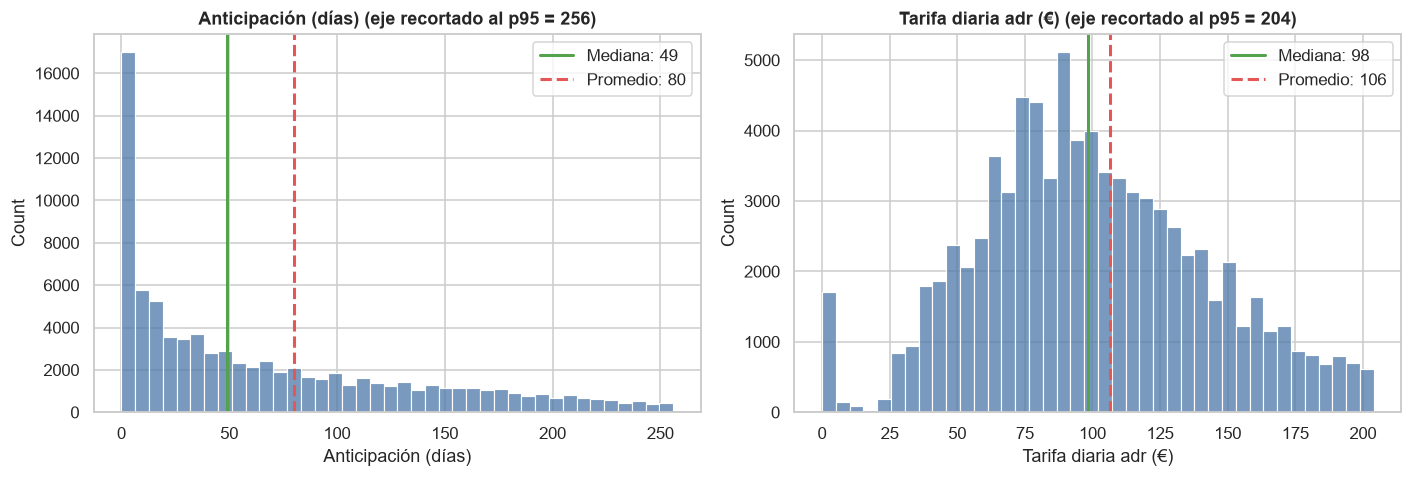

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, nombre in zip(ax, ["lead_time", "adr"], ["Anticipación (días)", "Tarifa diaria adr (€)"]):
    lim = df_eda[col].quantile(0.95)
    sns.histplot(df_eda[df_eda[col] <= lim], x=col, bins=40, color="#4C78A8", edgecolor="white", ax=a)
    a.axvline(df_eda[col].median(), color="#54A24B", lw=2, label=f"Mediana: {df_eda[col].median():.0f}")
    a.axvline(df_eda[col].mean(), color="#E45756", ls="--", lw=2, label=f"Promedio: {df_eda[col].mean():.0f}")
    a.set_title(f"{nombre} (eje recortado al p95 = {lim:.0f})", fontweight="bold"); a.set_xlabel(nombre); a.legend()
plt.tight_layout(); plt.show()

**Interpretación.** La anticipación es muy asimétrica: un cuarto de las reservas se hace con ≤ 11 días y el 5 % con más de 256. La tarifa se concentra entre 70 y 126 € (cuartiles) con cola larga hacia arriba. Ambas se usarán como numéricas sin transformar (los modelos de árboles no lo necesitan; para la logística se escalan).

## 4.3 Distribución del target

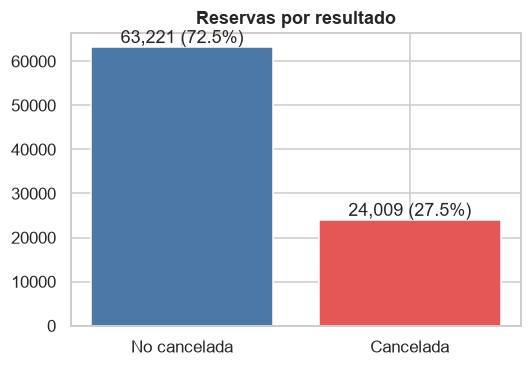

In [23]:
vc = df_eda.is_canceled.value_counts().rename({0: "No cancelada", 1: "Cancelada"})
plt.figure(figsize=(5, 3.5)); bars = plt.bar(vc.index, vc.values, color=["#4C78A8", "#E45756"])
plt.bar_label(bars, labels=[f"{v:,} ({v/n:.1%})" for v in vc.values]); plt.title("Reservas por resultado", fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretación.** Clase minoritaria del 27,5 %: desbalance moderado. Esto obliga a reportar PR-AUC además de ROC-AUC, a mostrar el modelo Dummy y a barrer el umbral en lugar de usar 0,5 por defecto.

## 4.4 Relación de la anticipación con el target
`lead_time` fue la numérica más correlacionada; la miramos por rangos con las tres métricas.

,lead_bin,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0-7,18203,1532,0.39,8.4
1,8-30,16326,4145,1.77,25.4
2,31-90,22720,7280,3.31,32.0
3,91-180,18224,6380,3.46,35.0
4,>180,11757,4672,2.56,39.7


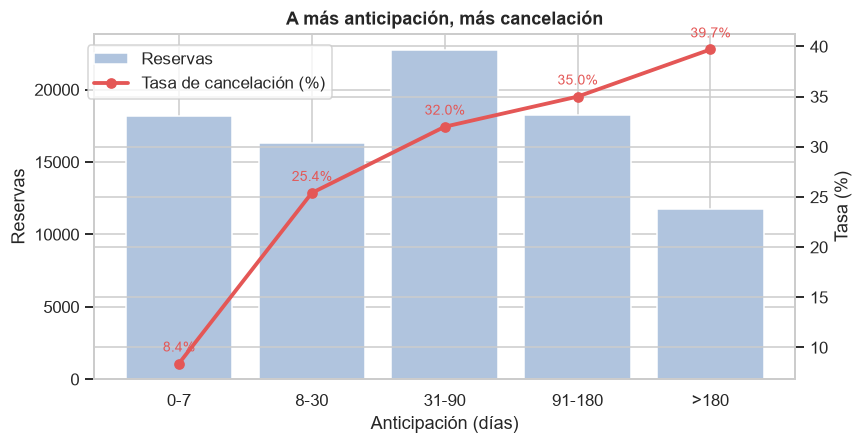

In [24]:
t = tabla_dim("lead_bin").sort_values("lead_bin"); display(t)
fig, ax1 = plt.subplots(figsize=(8, 4.2))
ax1.bar(t.lead_bin.astype(str), t.Reservas, color="#B0C4DE", label="Reservas"); ax1.set_ylabel("Reservas"); ax1.set_xlabel("Anticipación (días)")
ax2 = ax1.twinx(); ax2.plot(t.lead_bin.astype(str), t["Tasa_%"], color="#E45756", marker="o", lw=2.5, label="Tasa de cancelación (%)"); ax2.set_ylabel("Tasa (%)")
for x, v in zip(t.lead_bin.astype(str), t["Tasa_%"]): ax2.text(x, v + 1.2, f"{v:.1f}%", ha="center", color="#E45756", fontsize=9)
plt.title("A más anticipación, más cancelación", fontweight="bold"); fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9)); plt.tight_layout(); plt.show()

**Interpretación.** La tasa sube de forma monótona: 8,4 % con ≤ 7 días, 25,4 % de 8 a 30, 32,0 % de 31 a 90, 35,0 % de 91 a 180 y 39,7 % con más de 180 días. El volumen se concentra en 31–90 días (22.720 reservas), donde ya se cancela una de cada tres. Es el candidato a hallazgo principal; en 4.10 comprobamos si se repite en el tiempo y si se explica por mezcla de segmentos.

## 4.5 Dimensión Hotel y estancia

,hotel,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,City Hotel,53274,16035,6.61,30.1
1,Resort Hotel,33956,7974,4.87,23.5


,noches,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,591,23,0.00,3.9
1,1,17169,3161,0.34,18.4
2,2-3,33561,9547,2.86,28.4
3,4-7,31077,9622,6.07,31.0
4,8-14,4468,1466,1.86,32.8
5,>14,364,190,0.35,52.2


,meal,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,BB,67907,18043,8.34,26.6
3,SC,9883,3418,1.16,34.6
2,HB,9080,2449,1.90,27.0
1,FB,360,99,0.08,27.5


,reserved_room_type,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,A,56436,14682,5.42,26.0
3,D,17376,5235,2.91,30.1
4,E,6036,1646,1.14,27.3
5,F,2820,851,0.65,30.2
6,G,2050,737,0.72,36.0
1,B,996,317,0.12,31.8
2,C,914,296,0.28,32.4
7,H,596,243,0.24,40.8
8,L,6,2,0.00,33.3


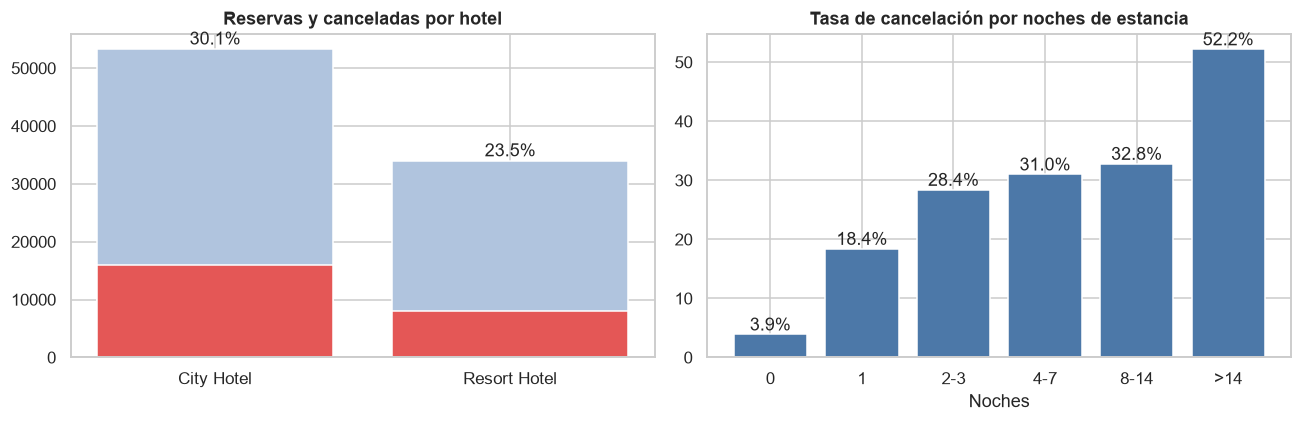

In [25]:
display(tabla_dim("hotel"))
display(tabla_dim(pd.cut(df_eda.total_nights, [-1, 0, 1, 3, 7, 14, 100], labels=["0", "1", "2-3", "4-7", "8-14", ">14"]).rename("noches")).sort_values("noches"))
display(tabla_dim("meal")); display(tabla_dim("reserved_room_type"))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
th = tabla_dim("hotel"); ax[0].bar(th.hotel, th.Reservas, color="#B0C4DE"); ax[0].bar(th.hotel, th.Canceladas, color="#E45756"); ax[0].set_title("Reservas y canceladas por hotel", fontweight="bold")
for i, r in th.iterrows(): ax[0].text(r.hotel, r.Reservas + 800, f"{r['Tasa_%']:.1f}%", ha="center")
tn = tabla_dim(pd.cut(df_eda.total_nights, [-1, 0, 1, 3, 7, 14, 100], labels=["0", "1", "2-3", "4-7", "8-14", ">14"]).rename("noches")).sort_values("noches")
ax[1].bar(tn.noches.astype(str), tn["Tasa_%"], color="#4C78A8"); ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%"); ax[1].set_title("Tasa de cancelación por noches de estancia", fontweight="bold"); ax[1].set_xlabel("Noches")
plt.tight_layout(); plt.show()

**Interpretación.** El City Hotel concentra el volumen (53.274 reservas, 61 %) y cancela más (30,1 % vs 23,5 % en el Resort): las diferencias están tanto en volumen como en eficiencia. Las estancias largas se cancelan más (52,2 % en > 14 noches, 32,8 % en 8–14) y las de 1 noche menos (18,4 %). El régimen SC (sin comidas) cancela más (34,6 %) y las habitaciones de tipo A (65 % del volumen) menos (26,0 %); las categorías G/H, menos frecuentes, superan el 36 %.

## 4.6 Dimensión Cliente

,customer_type,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
2,Transient,71862,21661,10.72,30.1
3,Transient-Party,11692,1783,0.50,15.2
0,Contract,3135,512,0.24,16.3
1,Group,541,53,0.02,9.8


,is_repeated_guest,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,83866,23749,11.42,28.3
1,1,3364,260,0.06,7.7


,cancelaciones_previas,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,85549,22866,11.08,26.7
1,1,1405,1070,0.38,76.2
2,≥2,276,73,0.02,26.4


,huespedes,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
1,2,57057,16100,7.05,28.2
0,1,16072,3094,1.01,19.3
2,3,10078,3160,1.96,31.4
3,≥4,4023,1655,1.46,41.1


,country,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
135,PRT,27355,9782,4.22,35.8
59,GBR,10424,1984,1.00,19.0
56,FRA,8823,1732,0.86,19.6
51,ESP,7244,1862,0.95,25.7
43,DEU,5385,1053,0.49,19.6
81,ITA,3061,1075,0.47,35.1
76,IRL,3015,668,0.36,22.2
15,BEL,2081,411,0.20,19.8
25,BRA,1993,727,0.35,36.5
123,NLD,1910,350,0.15,18.3


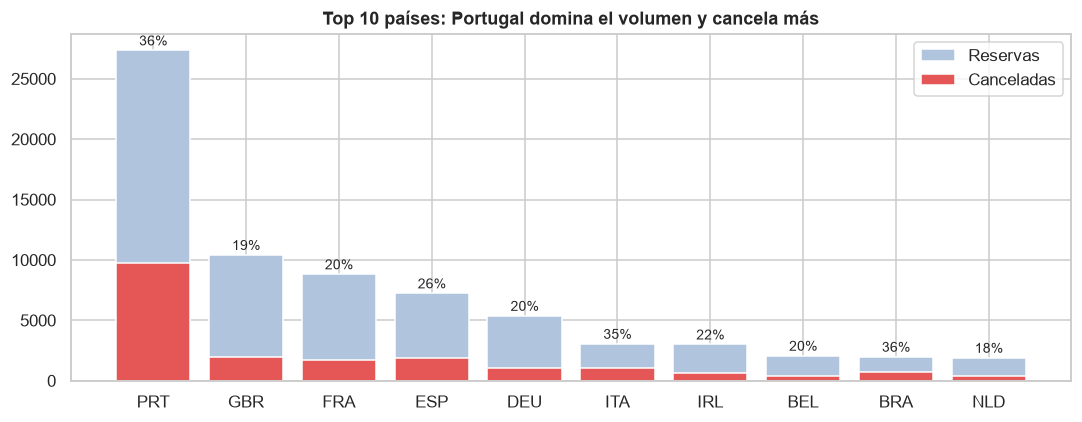

In [26]:
display(tabla_dim("customer_type")); display(tabla_dim("is_repeated_guest"))
display(tabla_dim(pd.cut(df_eda.previous_cancellations, [-1, 0, 1, 100], labels=["0", "1", "≥2"]).rename("cancelaciones_previas")))
display(tabla_dim(pd.cut(df_eda.total_guests, [0, 1, 2, 3, 100], labels=["1", "2", "3", "≥4"]).rename("huespedes")))
tc = tabla_dim("country", top=10); display(tc)
fig, ax = plt.subplots(figsize=(10, 4)); ax.bar(tc.country, tc.Reservas, color="#B0C4DE", label="Reservas"); ax.bar(tc.country, tc.Canceladas, color="#E45756", label="Canceladas")
for i, r in tc.iterrows(): ax.text(r.country, r.Reservas + 400, f"{r['Tasa_%']:.0f}%", ha="center", fontsize=9)
ax.set_title("Top 10 países: Portugal domina el volumen y cancela más", fontweight="bold"); ax.legend(); plt.tight_layout(); plt.show()

**Interpretación.** Portugal (mercado doméstico) aporta 27.355 reservas (31 %) y cancela 35,8 %, frente a 19–20 % de Reino Unido, Francia o Alemania; Italia y Brasil también superan el 35 % pero con poco volumen. Los clientes repetidos casi no cancelan (7,7 % vs 28,3 %) y quienes ya cancelaron antes una vez cancelan 76,2 %. Los *Transient* (82 % del volumen) cancelan el doble que los *Transient-Party* o *Contract*. Grupos de ≥ 4 huéspedes: 41,1 %.

## 4.7 Dimensión Canal

,market_segment,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
6,Online TA,51553,18242,9.29,35.4
5,Offline TA/TO,13855,2057,0.82,14.8
3,Direct,11780,1737,0.93,14.7
4,Groups,4922,1332,0.32,27.1
2,Corporate,4200,509,0.11,12.1
1,Complementary,692,85,0.00,12.3
0,Aviation,226,45,0.01,19.9
7,Undefined,2,2,0.00,100.0


,distribution_channel,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
3,TA/TO,69028,21400,10.36,31.0
1,Direct,12954,1923,0.96,14.8
0,Corporate,5062,646,0.15,12.8
2,GDS,181,36,0.01,19.9
4,Undefined,5,4,0.00,80.0


,has_agent,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
1,1,75089,22461,11.05,29.9
0,0,12141,1548,0.42,12.8


,has_company,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,81993,23440,11.38,28.6
1,1,5237,569,0.10,10.9


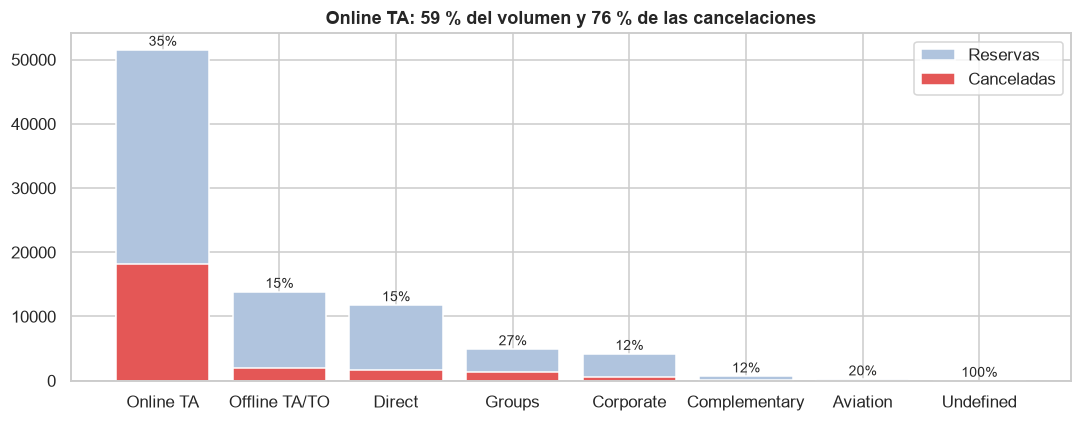

In [27]:
display(tabla_dim("market_segment")); display(tabla_dim("distribution_channel")); display(tabla_dim("has_agent")); display(tabla_dim("has_company"))
ts = tabla_dim("market_segment")
fig, ax = plt.subplots(figsize=(10, 4)); ax.bar(ts.market_segment, ts.Reservas, color="#B0C4DE", label="Reservas"); ax.bar(ts.market_segment, ts.Canceladas, color="#E45756", label="Canceladas")
for i, r in ts.iterrows(): ax.text(r.market_segment, r.Reservas + 600, f"{r['Tasa_%']:.0f}%", ha="center", fontsize=9)
ax.set_title("Online TA: 59 % del volumen y 76 % de las cancelaciones", fontweight="bold"); ax.legend(); plt.tight_layout(); plt.show()

**Interpretación.** *Online TA* (agencias en línea) es el canal dominante: 51.553 reservas (59 %) con 35,4 % de cancelación, y concentra 18.242 de las 24.009 cancelaciones (76 %) y 9,3 de los 11,5 M€ en riesgo. Los canales directos, corporativos y las agencias tradicionales cancelan entre 12 % y 15 %. Reservar sin agencia (12,8 %) o con empresa (10,9 %) se asocia a menos cancelación. Aquí las diferencias están en **eficiencia**, no solo en volumen.

## 4.8 Dimensión Tiempo: evolución por mes y año
Como 2015 y 2017 son incompletos, comparamos el mismo mes en distintos años.

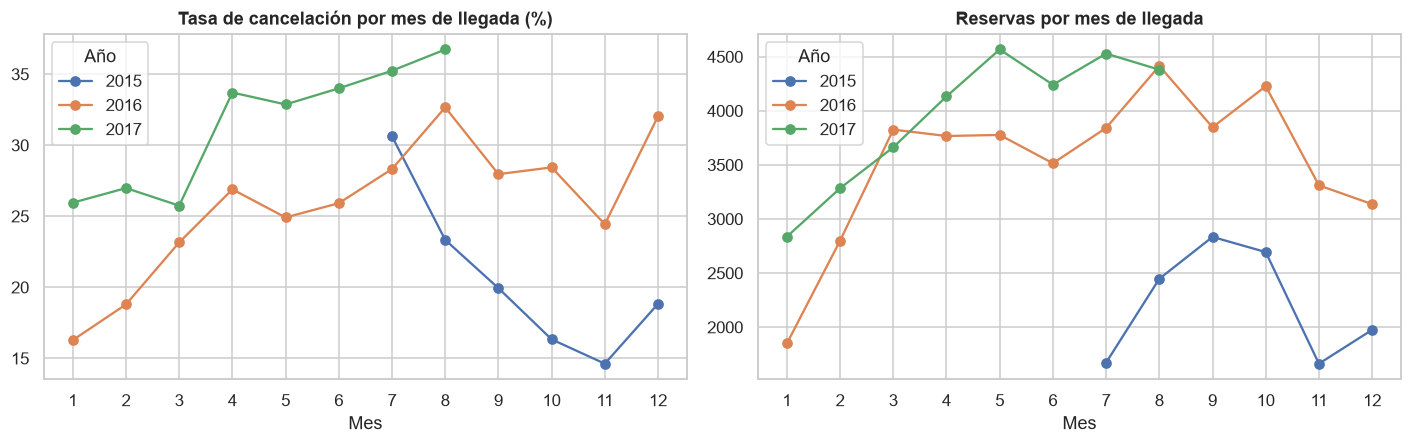

arrival_date_year,2015,2016,2017
arrival_quarter,,,
1,NaN,20.2,26.2
2,NaN,25.9,33.5
3,23.7,29.8,36.0
4,16.7,28.3,NaN


,arrival_dow,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
1,Monday,14148,3786,2.01,26.8
0,Friday,13317,4073,1.69,30.6
2,Saturday,13097,3946,2.01,30.1
4,Thursday,12964,3601,1.53,27.8
3,Sunday,11470,3052,1.62,26.6
6,Wednesday,11253,2877,1.32,25.6
5,Tuesday,10981,2674,1.29,24.4


In [28]:
ev = df_eda.groupby(["arrival_date_year", "arrival_month_num"]).is_canceled.agg(["size", "mean"]).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for y, g in ev.groupby("arrival_date_year"):
    ax[0].plot(g.arrival_month_num, g["mean"] * 100, marker="o", label=str(y)); ax[1].plot(g.arrival_month_num, g["size"], marker="o", label=str(y))
ax[0].set_title("Tasa de cancelación por mes de llegada (%)", fontweight="bold"); ax[0].set_xlabel("Mes"); ax[0].legend(title="Año"); ax[0].set_xticks(range(1, 13))
ax[1].set_title("Reservas por mes de llegada", fontweight="bold"); ax[1].set_xlabel("Mes"); ax[1].legend(title="Año"); ax[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()
display((df_eda.pivot_table(index="arrival_quarter", columns="arrival_date_year", values="is_canceled", aggfunc="mean") * 100).round(1))
display(tabla_dim("arrival_dow"))

**Interpretación.** Dos lecturas: (1) **estacionalidad**: la tasa es más alta en verano (abril–agosto, 30–37 %) y más baja en invierno (enero–febrero, 16–27 %); (2) **tendencia**: para el mismo mes, 2017 cancela más que 2016 y 2016 más que 2015 (julio: 30,6 → 28,3 → 35,2 %; agosto: 23,3 → 32,7 → 36,7 %). Esa tendencia es un aviso de *drift* para el modelo (sección 7.4). El día de la semana apenas importa (24–31 %).

## 4.9 Dimensión Condiciones de la reserva

In [29]:
display(tabla_dim("deposit_type"))
display(tabla_dim(pd.cut(df_eda.adr, [-1, 50, 80, 110, 150, 200, 1000], labels=["≤50", "51-80", "81-110", "111-150", "151-200", ">200"]).rename("adr_rango")).sort_values("adr_rango"))
display(tabla_dim(pd.cut(df_eda.total_of_special_requests, [-1, 0, 1, 2, 10], labels=["0", "1", "2", "≥3"]).rename("peticiones")))
display(tabla_dim(pd.cut(df_eda.booking_changes, [-1, 0, 1, 100], labels=["0", "1", "≥2"]).rename("cambios")))
display(tabla_dim(pd.cut(df_eda.required_car_parking_spaces, [-1, 0, 10], labels=["0", "≥1"]).rename("parqueo")))

,deposit_type,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,No Deposit,86085,23000,11.23,26.7
1,Non Refund,1038,983,0.24,94.7
2,Refundable,107,26,0.01,24.3


,adr_rango,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,≤50,9708,1455,0.21,15.0
1,51-80,19134,4310,1.22,22.5
2,81-110,23399,6457,2.35,27.6
3,111-150,19878,6484,3.21,32.6
4,151-200,10392,3530,2.51,34.0
5,>200,4717,1772,1.97,37.6


,peticiones,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,43789,14561,6.75,33.3
1,1,28976,6501,3.23,22.4
2,2,11795,2515,1.28,21.3
3,≥3,2670,432,0.22,16.2


,cambios,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,71425,21555,10.17,30.2
1,1,10868,1508,0.80,13.9
2,≥2,4937,946,0.51,19.2


,parqueo,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%
0,0,79924,24009,11.48,30.0
1,≥1,7306,0,0.00,0.0


**Interpretación.**
- `deposit_type`: *Non Refund* cancela 94,7 %, pero tras deduplicar son solo 1.038 reservas (1,2 %), casi todas de Portugal (983). Es una señal fuerte pero de poco alcance.
- `adr`: la tasa sube con la tarifa (15,0 % en ≤ 50 € hasta 37,6 % en > 200 €).
- Peticiones especiales y cambios: 0 peticiones → 33,3 %; ≥ 3 → 16,2 %. 0 cambios → 30,2 %; 1 cambio → 13,9 %. Son señales de compromiso del cliente.
- **Parqueo: 0 cancelaciones entre 7.306 reservas con plaza.** Una regla perfecta de este tipo no es comportamiento, es registro: la plaza se anota al llegar. Se trata como post-evento y queda fuera del modelo (ver 4.11).

## 4.10 Investigación especial: anticipación × origen del cliente
El patrón más fuerte es la anticipación. Comprobamos (1) si se repite cada año y en cada hotel, (2) qué lo amplifica, (3) si es un efecto de mezcla de segmentos y (4) cuánto pesa.

In [30]:
print("1) ¿Se repite? Tasa (%) por rango de anticipación, por año y por hotel")
display((df_eda.pivot_table(index="lead_bin", columns="arrival_date_year", values="is_canceled", aggfunc="mean", observed=True) * 100).round(1))
display((df_eda.pivot_table(index="lead_bin", columns="hotel", values="is_canceled", aggfunc="mean", observed=True) * 100).round(1))

1) ¿Se repite? Tasa (%) por rango de anticipación, por año y por hotel


arrival_date_year,2015,2016,2017
lead_bin,,,
0-7,8.2,8.7,8.0
8-30,17.8,26.2,28.1
31-90,23.5,32.4,35.8
91-180,30.3,33.1,38.4
>180,39.4,33.9,45.3


hotel,City Hotel,Resort Hotel
lead_bin,,
0-7,10.5,6.0
8-30,27.9,20.9
31-90,33.2,29.8
91-180,36.7,32.0
>180,44.9,33.9


**Lectura.** La tasa crece con la anticipación en los tres años y en los dos hoteles (City: 10,5 → 44,9 %; Resort: 6,0 → 33,9 %). El patrón es **estructural**, no de un periodo.

2) ¿Qué lo amplifica? Anticipación × origen (Portugal vs. otros)


Tasa_%              Reservas         
es_PRT   Otros países Portugal Otros países Portugal
lead_bin                                            
0-7               5.6     11.1         8759     9444
8-30             21.8     33.4        11311     5015
31-90            27.2     46.8        17155     5565
91-180           28.8     55.1        13940     4284
>180             29.6     68.8         8710     3047

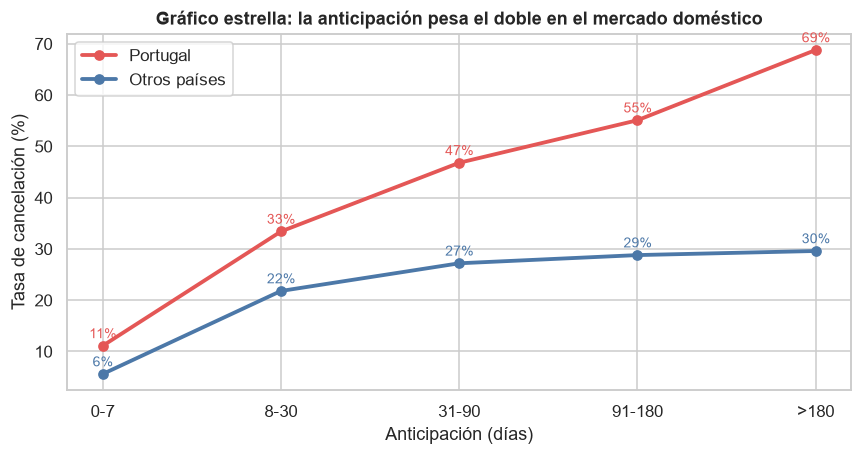

In [31]:
print("2) ¿Qué lo amplifica? Anticipación × origen (Portugal vs. otros)")
piv_t = (df_eda.pivot_table(index="lead_bin", columns="es_PRT", values="is_canceled", aggfunc="mean", observed=True) * 100).round(1)
piv_n = df_eda.pivot_table(index="lead_bin", columns="es_PRT", values="is_canceled", aggfunc="size", observed=True)
display(pd.concat({"Tasa_%": piv_t, "Reservas": piv_n}, axis=1))
fig, ax = plt.subplots(figsize=(8, 4.3))
for col, color in zip(["Portugal", "Otros países"], ["#E45756", "#4C78A8"]):
    ax.plot(piv_t.index.astype(str), piv_t[col], marker="o", lw=2.5, color=color, label=col)
    for x, v in zip(piv_t.index.astype(str), piv_t[col]): ax.text(x, v + 1.5, f"{v:.0f}%", ha="center", color=color, fontsize=9)
ax.set_xlabel("Anticipación (días)"); ax.set_ylabel("Tasa de cancelación (%)"); ax.legend()
ax.set_title("Gráfico estrella: la anticipación pesa el doble en el mercado doméstico", fontweight="bold"); plt.tight_layout(); plt.show()

**Lectura.** Con ≤ 7 días, Portugal cancela 11,1 % y el resto 5,6 %; con más de 180 días, Portugal cancela **68,8 %** y el resto 29,6 %. La anticipación eleva la tasa en todos los mercados, pero en el doméstico la multiplica por seis. Portugal además reserva con menos anticipación (mediana 25 vs 60 días), así que su mayor tasa **no** se debe a que reserve antes.

In [32]:
print("3) ¿Es mezcla de segmentos? Tasa (%) Portugal vs. otros dentro de cada segmento y de cada tipo de cliente")
seg = pd.concat({"Tasa_%": (df_eda.pivot_table(index="market_segment", columns="es_PRT", values="is_canceled", aggfunc="mean", observed=True) * 100).round(1),
                 "Reservas": df_eda.pivot_table(index="market_segment", columns="es_PRT", values="is_canceled", aggfunc="size", observed=True)}, axis=1)
display(seg)
cumple = (seg[("Tasa_%", "Portugal")] > seg[("Tasa_%", "Otros países")]).sum()
print(f"Portugal cancela más que el resto en {cumple} de {seg.shape[0]} segmentos; en {(piv_t['Portugal'] > piv_t['Otros países']).sum()} de {len(piv_t)} rangos de anticipación")
display((df_eda.pivot_table(index=["hotel", "arrival_date_year"], columns="es_PRT", values="is_canceled", aggfunc="mean", observed=True) * 100).round(1))

3) ¿Es mezcla de segmentos? Tasa (%) Portugal vs. otros dentro de cada segmento y de cada tipo de cliente


Tasa_%              Reservas         
es_PRT         Otros países Portugal Otros países Portugal
market_segment                                            
Aviation                7.8     36.1        129.0     97.0
Complementary           1.4     13.5         69.0    623.0
Corporate               2.9     14.9        969.0   3231.0
Direct                 10.7     19.3       6293.0   5487.0
Groups                  1.6     58.3       2712.0   2210.0
Offline TA/TO           0.5     43.4       9227.0   4628.0
Online TA              33.2     43.5      40476.0  11077.0
Undefined               NaN    100.0          NaN      2.0

Portugal cancela más que el resto en 7 de 8 segmentos; en 5 de 5 rangos de anticipación


es_PRT                          Otros países  Portugal
hotel        arrival_date_year                        
City Hotel   2015                        2.3      41.4
             2016                       28.3      32.0
             2017                       32.3      42.5
Resort Hotel 2015                        1.2      35.8
             2016                       12.8      34.3
             2017                       25.3      33.7

**Lectura.** No es mezcla: Portugal cancela más en **los 7 segmentos con reservas de ambos orígenes** (el octavo, *Undefined*, solo tiene 2 reservas, ambas portuguesas), incluido *Online TA* (43,5 % vs 33,2 %); en los 5 rangos de anticipación, en ambos hoteles y en los tres años. El contraste más llamativo está en *Offline TA/TO* (43,4 % vs 0,5 %) y *Groups* (58,3 % vs 1,6 %): las reservas internacionales por operador casi nunca se cancelan; las domésticas sí.

In [33]:
print("4) Mecanismo y cuantificación")
mec = df_eda.groupby("es_PRT").agg(lead_mediana=("lead_time", "median"), pct_non_refund=("deposit_type", lambda s: (s == "Non Refund").mean() * 100),
                                    pct_cancel_previa=("previous_cancellations", lambda s: (s > 0).mean() * 100), pct_sin_peticiones=("total_of_special_requests", lambda s: (s == 0).mean() * 100),
                                    pct_online=("market_segment", lambda s: (s == "Online TA").mean() * 100), pct_groups_offline=("market_segment", lambda s: s.isin(["Groups", "Offline TA/TO"]).mean() * 100)).round(1)
display(mec)
tp = tabla_dim("es_PRT"); tp["%_reservas"] = (tp.Reservas / n * 100).round(1); tp["%_canceladas"] = (tp.Canceladas / canc * 100).round(1)
tp["%_ingreso_riesgo"] = (tp.Ingreso_riesgo_M / df_eda.loc[df_eda.is_canceled == 1, "ingreso_estimado"].sum() * 1e6 * 100).round(1); display(tp)

4) Mecanismo y cuantificación


,lead_mediana,pct_non_refund,pct_cancel_previa,pct_sin_peticiones,pct_online,pct_groups_offline
es_PRT,,,,,,
Otros países,60.0,0.1,0.2,46.9,67.6,19.9
Portugal,25.0,3.6,5.8,57.4,40.5,25.0


,es_PRT,Reservas,Canceladas,Ingreso_riesgo_M,Tasa_%,%_reservas,%_canceladas,%_ingreso_riesgo
0,Otros países,59875,14227,7.25,23.8,68.6,59.3,63.2
1,Portugal,27355,9782,4.22,35.8,31.4,40.7,36.8


**Lectura.** Portugal es el 31,4 % de las reservas pero el 40,7 % de las cancelaciones y el 36,8 % del ingreso en riesgo. El depósito *Non Refund* **no** lo explica (3,6 % de sus reservas). Lo que sí lo acompaña: el 5,8 % de los clientes portugueses ya había cancelado antes (0,2 % en el resto), reservan con menos peticiones especiales (57 % sin ninguna vs 47 %) y llegan más por *Groups/Offline TA* (25 % vs 20 %), canales donde su tasa es extrema.

**Conclusión de la investigación (asociación observacional consistente, no causal):** cancelar está asociado sobre todo con *cuánto tiempo antes* se reservó y con *desde dónde*: la anticipación eleva la tasa en todos los mercados y el mercado doméstico la amplifica en todos los canales. Pregunta que abre: ¿puede un modelo anticipar, reserva a reserva, cuáles se cancelarán combinando anticipación, origen, canal y señales de compromiso?

## 4.11 Verificación: ¿`assigned_room_type` y el parqueo son post-evento?

In [34]:
display(pd.crosstab(df_eda.room_changed.map({0: "misma habitación", 1: "cambió de habitación"}), df_eda.is_canceled, normalize="index").round(3).rename(columns={0: "no cancelada", 1: "cancelada"}))
display(pd.crosstab(df_eda.required_car_parking_spaces.gt(0).map({False: "sin parqueo", True: "con parqueo"}), df_eda.is_canceled).rename(columns={0: "no cancelada", 1: "cancelada"}))

is_canceled,no cancelada,cancelada
room_changed,,
cambió de habitación,0.953,0.047
misma habitación,0.685,0.315


is_canceled,no cancelada,cancelada
required_car_parking_spaces,,
con parqueo,7306,0
sin parqueo,55915,24009


**Decisión.** Las reservas que cambiaron de habitación se cancelan 4,7 % (vs 31,5 % las que no) y las que tienen plaza de parqueo 0,0 %: ambas variables reflejan lo que ocurre **al llegar**, no al reservar. Quedan como `post_event_columns`; en 7.3 mostramos cuánto subiría el AUC si se incluyeran (y por qué sería fuga).

# 5. Conclusiones del EDA

1. **Volumen ≠ eficiencia.** El City Hotel y *Online TA* dominan el volumen (61 % y 59 % de las reservas) y además cancelan más (30,1 % y 35,4 %); *Online TA* concentra el 76 % de las cancelaciones y 9,3 de los 11,5 M€ en riesgo.
2. **Canales directos y corporativos son estables.** Direct, Corporate y Offline TA/TO cancelan 12–15 %; reservar sin agencia (12,8 %) o con empresa (10,9 %) se asocia a menos cancelación.
3. **Hallazgo principal: la anticipación.** La tasa sube de 8,4 % (≤ 7 días) a 39,7 % (> 180 días), en los tres años y en ambos hoteles.
4. **Amplificador: el mercado doméstico.** Portugal (31 % de las reservas, 41 % de las cancelaciones) cancela más en 7 de 7 segmentos y en los 5 rangos de anticipación; con > 180 días llega a 68,8 % frente a 29,6 %. No es mezcla de canales ni efecto del depósito.
5. **Señales de compromiso.** Cliente repetido (7,7 %), peticiones especiales (≥ 3: 16,2 %) y cambios en la reserva (1 cambio: 13,9 %) se asocian a menos cancelación; una cancelación previa, a mucha más (76,2 %).
6. **Lo que no se puede afirmar.** No podemos decir que la anticipación o el origen *causen* la cancelación: son asociaciones. Tampoco sabemos si las filas duplicadas eran bloques reales; la tasa de 27,5 % es la del dataset deduplicado. El parqueo y la habitación asignada se descartan por ser datos de check-in.

> **Pregunta final que deja el EDA:** ¿con qué precisión puede un modelo anticipar, reserva a reserva, cuáles se cancelarán usando solo lo que se conoce al reservar (anticipación, origen, canal, estancia, condiciones y señales de compromiso), y qué variables pesan más una vez se controlan todas a la vez?

**Posibles continuaciones:** clasificación binaria con umbral de negocio (lo que sigue); pruebas de hipótesis Portugal vs. resto por segmento; segmentación de clientes de alto riesgo; política de depósitos diferenciada por anticipación y mercado.

# 6. Modelado: ¿qué reservas se van a cancelar?

## 6.1 Librerías y carga del CSV limpio
Las etapas de modelado leen el CSV limpio, no el crudo. `agent`/`company` se leen como texto porque son códigos.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score, train_test_split
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report, roc_curve, precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)

dm = pd.read_csv("data/hotel_bookings_limpio.csv", dtype={"agent": str, "company": str}, parse_dates=["arrival_date", "reservation_status_date"])
dm["room_changed"] = (dm.reserved_room_type != dm.assigned_room_type).astype(int)
print(dm.shape)

(87230, 40)


## 6.2 Target
Clasificación binaria: clase 1 = reserva cancelada o no-show (el evento a detectar). Métricas: ROC-AUC (calidad del ranking), PR-AUC (piso = prevalencia), F1 y matriz de confusión al umbral de negocio.

In [36]:
y_all = dm["is_canceled"]
print(f"Prevalencia: {y_all.mean():.2%} ({y_all.sum():,} de {len(y_all):,})")

Prevalencia: 27.52% (24,009 de 87,230)


## 6.3 Variables y prevención de fuga
Tres listas explícitas y un `assert`. Cada exclusión con su motivo:

| Columna(s) | Motivo de exclusión |
|---|---|
| reservation_status, reservation_status_date | **fuga**: el target se deriva de ellas |
| assigned_room_type, room_changed, required_car_parking_spaces | **post-evento**: se registran al check-in (4.11) |
| company | redundante con `has_company` (94 % "SinEmpresa"; 352 códigos) |
| arrival_date_year, arrival_date_week_number, arrival_date_day_of_month, arrival_date, year_month, arrival_quarter, arrival_month_num | redundantes con `arrival_date_month` (categórico) y `arrival_dow`; el año no generaliza a periodos futuros |
| total_nights, total_guests, ingreso_estimado, lead_bin, es_PRT | derivadas de otras features ya incluidas (o del adr y noches) |

`booking_changes` y `days_in_waiting_list` se conservan ⚠️ asumiendo que están disponibles cuando el hotel usaría la predicción; se vigilan en 7.3.

In [37]:
numeric_features = ["lead_time", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies", "is_repeated_guest",
                    "previous_cancellations", "previous_bookings_not_canceled", "booking_changes", "days_in_waiting_list", "adr",
                    "total_of_special_requests", "has_agent", "has_company"]
nominal_features = ["hotel", "meal", "country", "market_segment", "distribution_channel", "reserved_room_type", "deposit_type",
                    "customer_type", "agent", "arrival_date_month", "arrival_dow"]
features = numeric_features + nominal_features
leakage_columns    = ["reservation_status", "reservation_status_date"]
post_event_columns = ["assigned_room_type", "room_changed", "required_car_parking_spaces"]
id_columns         = []
assert not set(features) & set(leakage_columns + post_event_columns + id_columns)
dimension = {**{c: "Hotel y estancia" for c in ["hotel", "stays_in_weekend_nights", "stays_in_week_nights", "reserved_room_type", "meal"]},
             **{c: "Cliente" for c in ["adults", "children", "babies", "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled", "customer_type", "country"]},
             **{c: "Canal" for c in ["market_segment", "distribution_channel", "agent", "has_agent", "has_company"]},
             **{c: "Tiempo y anticipación" for c in ["lead_time", "days_in_waiting_list", "arrival_date_month", "arrival_dow"]},
             **{c: "Condiciones" for c in ["deposit_type", "adr", "booking_changes", "total_of_special_requests"]}}
assert set(dimension) == set(features)
X_all = dm[features]
print(len(features), "features:", len(numeric_features), "numéricas +", len(nominal_features), "nominales. Assert de fuga: OK")

26 features: 15 numéricas + 11 nominales. Assert de fuga: OK


## 6.4 Partición train / test
75/25 estratificada. Test se toca **una sola vez**, en 6.7. No hay grupos (cliente, pedido) con los que validar `GroupKFold`; la verificación por tiempo se hace en 7.4.

In [38]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.25, stratify=y_all, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} (prevalencia {y_train.mean():.2%}) | Test: {X_test.shape} (prevalencia {y_test.mean():.2%})")

Train: (65422, 26) (prevalencia 27.52%) | Test: (21808, 26) (prevalencia 27.52%)


## 6.5 Preprocesamiento en cuatro etapas
Un `ColumnTransformer` con dos ramas (numéricas, nominales). Cada etapa se decide por validación cruzada (3 folds) sobre una **submuestra de 6.000 filas de train** con la regresión logística como modelo de referencia, con criterio desempeño + parsimonia (diferencia < 0,01 de AUC → gana lo simple).

In [39]:
def crear_preprocesador(imputacion="simple", scaler=None, subset_features=None, min_frequency=100):
    feats = subset_features or features
    num = [c for c in numeric_features if c in feats]; nom = [c for c in nominal_features if c in feats]
    tr = []
    if num:
        imputer = KNNImputer(n_neighbors=5) if imputacion == "knn" else SimpleImputer(strategy="median")
        pasos = [("imputer", imputer)]
        if scaler is not None: pasos.append(("scaler", clone(scaler)))
        tr.append(("num", Pipeline(pasos), num))
        if imputacion == "indicator": tr.append(("miss", MissingIndicator(features="all"), num))
    if nom:
        tr.append(("nom", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency, sparse_output=False))]), nom))
    return ColumnTransformer(tr, remainder="drop")

baseline = LogisticRegression(max_iter=2000)
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
X_sub = X_train.sample(n=6000, random_state=RANDOM_STATE); y_sub = y_train.loc[X_sub.index]
scoring = {"auc": "roc_auc", "ap": "average_precision"}

def evaluar_cv(pipe, Xs, ys, cv):
    t = time.time(); s = cross_validate(pipe, Xs, ys, cv=cv, scoring=scoring, n_jobs=-1)
    return {"AUC_CV": s["test_auc"].mean(), "AUC_std": s["test_auc"].std(), "PR_AUC_CV": s["test_ap"].mean(), "Tiempo_s": time.time() - t}

### Etapa 1 — Imputación
Solo `adr` tiene nulos (2 filas en todo el dataset), así que esperamos un empate.

In [40]:
res = [{"Estrategia": k, **evaluar_cv(Pipeline([("prep", crear_preprocesador(k, StandardScaler())), ("model", clone(baseline))]), X_sub, y_sub, cv3)} for k in ["simple", "knn", "indicator"]]
display(pd.DataFrame(res).round(4))
mejor_imputacion = "simple"

,Estrategia,AUC_CV,AUC_std,PR_AUC_CV,Tiempo_s
0,simple,0.8075,0.011,0.6191,2.5314
1,knn,0.8075,0.011,0.6191,1.8290
2,indicator,0.8075,0.011,0.6191,1.8012


**Decisión de Etapa 1.** Empate exacto (AUC 0,8075 las tres): con 2 nulos no hay nada que aprender. Se elige `SimpleImputer(median)` por parsimonia.

### Etapa 2 — Codificación
Nominales con One-Hot y agrupación de categorías raras (`min_frequency`): probamos sin agrupar, 20, 100 y 500 filas mínimas. Como contraste didáctico, "todo como ordinal" (enteros arbitrarios a las nominales).

In [41]:
res = [{"min_frequency": str(mf), **evaluar_cv(Pipeline([("prep", crear_preprocesador("simple", StandardScaler(), min_frequency=mf)), ("model", clone(baseline))]), X_sub, y_sub, cv3)} for mf in [None, 20, 100, 500]]
prep_ord = ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), numeric_features),
                              ("ord", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")), ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)), ("sc", StandardScaler())]), nominal_features)])
res.append({"min_frequency": "todo ordinal (contraste)", **evaluar_cv(Pipeline([("prep", prep_ord), ("model", clone(baseline))]), X_sub, y_sub, cv3)})
display(pd.DataFrame(res).round(4))
ej = crear_preprocesador("simple", None, subset_features=["hotel", "deposit_type", "lead_time"]).fit(X_train)
print("Ejemplo One-Hot:", list(ej.get_feature_names_out()))
mejor_min_frequency = 100

,min_frequency,AUC_CV,AUC_std,PR_AUC_CV,Tiempo_s
0,None,0.8095,0.0096,0.6282,1.8366
1,20,0.8089,0.0097,0.6268,0.1235
2,100,0.8075,0.0110,0.6191,0.1080
3,500,0.8064,0.0093,0.6132,0.0880
4,todo ordinal (contraste),0.7530,0.0014,0.5616,0.0560


Ejemplo One-Hot: ['num__lead_time', 'nom__hotel_City Hotel', 'nom__hotel_Resort Hotel', 'nom__deposit_type_No Deposit', 'nom__deposit_type_Non Refund', 'nom__deposit_type_infrequent_sklearn']


**Decisión de Etapa 2.** Sin agrupar da AUC 0,8095 y con mínimo 100 filas 0,8075: diferencia de 0,002 a cambio de pasar de cientos de columnas a decenas (país: 36 categorías + "infrecuente"; agencia: 59). Elegimos `min_frequency = 100` por parsimonia e interpretabilidad. "Todo ordinal" cae a 0,753: imponer un orden a país o segmento degrada el modelo lineal. Mes y día de semana se tratan como **categóricos** para no imponer linealidad.

### Etapa 3 — Escalado

In [42]:
res = [{"Escalado": nm, **evaluar_cv(Pipeline([("prep", crear_preprocesador("simple", sc)), ("model", clone(baseline))]), X_sub, y_sub, cv3)}
       for nm, sc in {"Sin escalar": None, "StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}.items()]
display(pd.DataFrame(res).round(4))
mejor_scaler = StandardScaler()

,Escalado,AUC_CV,AUC_std,PR_AUC_CV,Tiempo_s
0,Sin escalar,0.8075,0.0109,0.6194,0.6398
1,StandardScaler,0.8075,0.0110,0.6191,0.0989
2,MinMaxScaler,0.8024,0.0105,0.6102,0.1083
3,RobustScaler,0.8075,0.0110,0.6191,0.1497


**Decisión de Etapa 3.** Standard y Robust empatan con "sin escalar" (0,8075); MinMax baja levemente (0,8024) porque comprime `lead_time` y `adr` por sus máximos. Elegimos `StandardScaler`: no cambia el desempeño de la logística pero hace comparables sus coeficientes (y es indiferente para los árboles).

### Etapa 4 — Texto
No hay texto libre: `agent` y `country` son códigos (nominales con agrupación de raros); `company` se redujo a bandera. Nada que vectorizar.

In [43]:
preprocesador = crear_preprocesador(mejor_imputacion, mejor_scaler, min_frequency=mejor_min_frequency)
print("Columnas tras el preprocesador:", preprocesador.fit(X_train).transform(X_train.head()).shape[1])

Columnas tras el preprocesador: 156


## 6.6 Experimentación con validación cruzada (5 folds sobre train)
Modelos en orden de complejidad, desde el Dummy. Tabla con AUC (media ± std), PR-AUC y tiempo.

In [44]:
modelos = {"Dummy": DummyClassifier(strategy="most_frequent"),
           "Regresión logística": LogisticRegression(max_iter=2000),
           "Árbol de decisión": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
           "KNN": KNeighborsClassifier(n_neighbors=25),
           "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
           "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE)}
pipelines = {nm: Pipeline([("prep", clone(preprocesador)), ("model", est)]) for nm, est in modelos.items()}
tabla_modelos = pd.DataFrame([{"Modelo": nm, **evaluar_cv(p, X_train, y_train, cv5)} for nm, p in pipelines.items()]).sort_values("AUC_CV", ascending=False)
display(tabla_modelos.round(4))

,Modelo,AUC_CV,AUC_std,PR_AUC_CV,Tiempo_s
4,Random Forest,0.8899,0.0026,0.7629,19.0449
5,Gradient Boosting,0.8879,0.0021,0.7592,7.6013
2,Árbol de decisión,0.8406,0.0072,0.6380,1.3840
1,Regresión logística,0.8292,0.0028,0.6485,2.7478
3,KNN,0.8259,0.0042,0.6574,7.2604
0,Dummy,0.5000,0.0000,0.2752,0.7968


In [45]:
reales = tabla_modelos[tabla_modelos.Modelo != "Dummy"]
mejor_auc = reales.AUC_CV.max()
empatados = reales[reales.AUC_CV >= mejor_auc - 0.002].copy()
prioridad = {"Regresión logística": 1, "Árbol de decisión": 2, "KNN": 3, "Gradient Boosting": 4, "Random Forest": 5}
empatados["Prioridad"] = empatados.Modelo.map(prioridad)
mejor_nombre = empatados.sort_values(["Prioridad", "AUC_CV"]).iloc[0].Modelo
print("Empate estadístico (±0,002 AUC):", empatados.Modelo.tolist(), "→ elegido por parsimonia:", mejor_nombre)

Empate estadístico (±0,002 AUC): ['Random Forest', 'Gradient Boosting'] → elegido por parsimonia: Gradient Boosting


### Decisión
Random Forest (AUC 0,890) y Gradient Boosting (0,888) empatan dentro de ±0,002; KNN, el árbol y la logística quedan claramente por debajo (0,826–0,841), así que **no** hay argumento de parsimonia para el modelo lineal: la relación no es aditiva (interacciones anticipación × origen × canal, como mostró el EDA). Entre los dos empatados elegimos **Gradient Boosting**: más del doble de rápido (8 s vs 19 s), menos memoria y entrenamiento determinista. Alternativa descartada: Random Forest (misma calidad, más lento).

## 6.7 Evaluación en test del modelo base
Test se usa solo para **reportar**, nunca para elegir (la selección se hizo en CV). Aquí evaluamos el Gradient Boosting base; en 7.5, tras el tuning, se decide si un afinado lo reemplaza como modelo final.

ROC-AUC test: 0.8940 | PR-AUC test: 0.7685 (piso = prevalencia 0.275)
Umbral 0,5 → TN 14,474 | FP 1,332 | FN 2,335 | TP 3,667 | accuracy 0.832 | precision 0.734 | recall 0.611 | F1 0.667 | especificidad 0.916


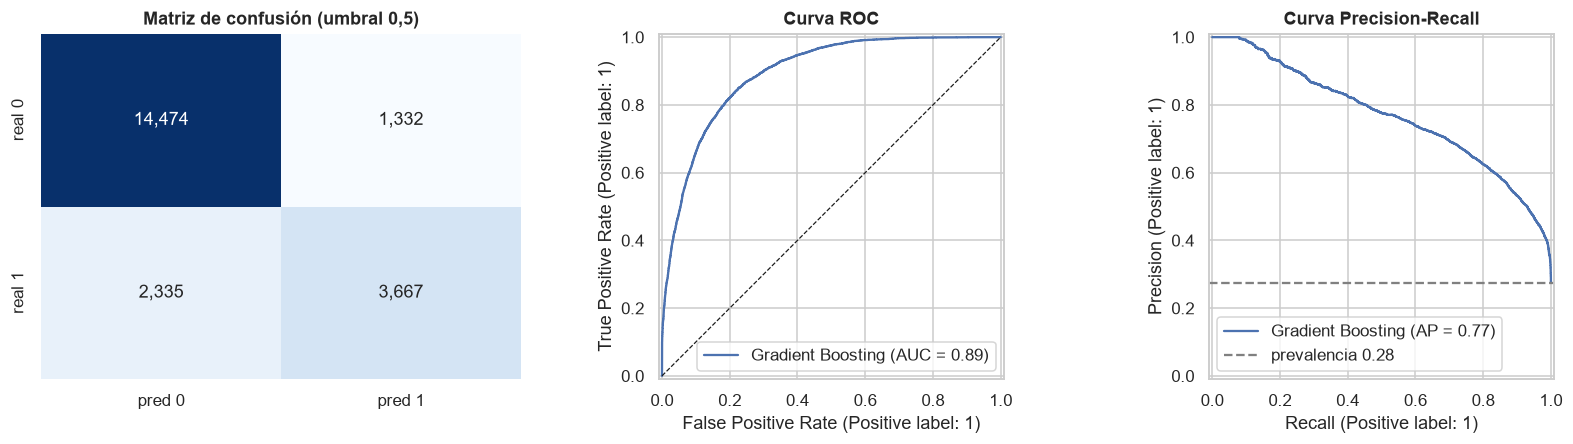

In [46]:
pipe_final = pipelines[mejor_nombre].fit(X_train, y_train)
proba_test = pipe_final.predict_proba(X_test)[:, 1]
pred05 = (proba_test >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred05).ravel()
auc_test = roc_auc_score(y_test, proba_test); ap_test = average_precision_score(y_test, proba_test)
print(f"ROC-AUC test: {auc_test:.4f} | PR-AUC test: {ap_test:.4f} (piso = prevalencia {y_test.mean():.3f})")
print(f"Umbral 0,5 → TN {tn:,} | FP {fp:,} | FN {fn:,} | TP {tp:,} | accuracy {(tn+tp)/len(y_test):.3f} | precision {tp/(tp+fp):.3f} | recall {tp/(tp+fn):.3f} | F1 {f1_score(y_test, pred05):.3f} | especificidad {tn/(tn+fp):.3f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.heatmap(confusion_matrix(y_test, pred05), annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[0], xticklabels=["pred 0", "pred 1"], yticklabels=["real 0", "real 1"]); ax[0].set_title("Matriz de confusión (umbral 0,5)", fontweight="bold")
RocCurveDisplay.from_predictions(y_test, proba_test, ax=ax[1], name=mejor_nombre); ax[1].plot([0, 1], [0, 1], "k--", lw=0.8); ax[1].set_title("Curva ROC", fontweight="bold")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax[2], name=mejor_nombre); ax[2].axhline(y_test.mean(), color="gray", ls="--", label=f"prevalencia {y_test.mean():.2f}"); ax[2].legend(); ax[2].set_title("Curva Precision-Recall", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretación.** En test (21.808 reservas nunca vistas) el modelo alcanza ROC-AUC 0,894 y PR-AUC 0,769 (frente a un piso de 0,275): ordena bien el riesgo. Al umbral 0,5 detecta 3.667 de las 6.002 cancelaciones (recall 61 %) con 1.332 falsas alarmas (precision 73 %) y F1 0,667; la accuracy de 0,83 se lee con cuidado porque predecir "nadie cancela" ya daría 0,72.

## 6.8 Umbral de negocio
Barremos umbrales de 0,05 a 0,95 y proponemos tres: máximo F1, recall ≥ 80 % y 0,5.

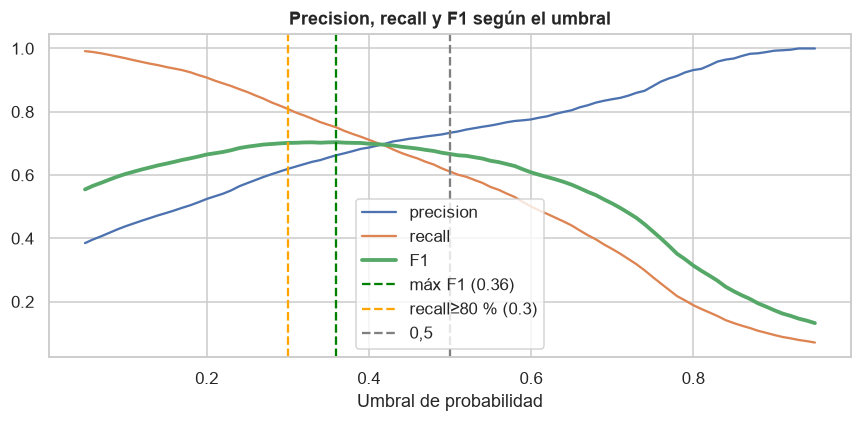

,umbral,precision,recall,f1,alertas
25,0.30,0.619,0.809,0.702,7842
31,0.36,0.663,0.751,0.704,6797
45,0.50,0.734,0.611,0.667,4999


Al umbral 0.36: TP 4,505 | FN 1,497 | FP 2,292 | TN 13,514  → de 6,002 cancelaciones detectamos 4,505; alertamos 2,292 que no cancelaron


In [47]:
umbrales = np.arange(0.05, 0.96, 0.01)
tabla_u = pd.DataFrame([{"umbral": round(t, 2), "precision": precision_score(y_test, proba_test >= t, zero_division=0), "recall": recall_score(y_test, proba_test >= t),
                         "f1": f1_score(y_test, proba_test >= t), "alertas": int((proba_test >= t).sum())} for t in umbrales])
t_f1 = tabla_u.loc[tabla_u.f1.idxmax(), "umbral"]; t_rec80 = tabla_u[tabla_u.recall >= 0.80].umbral.max()
fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(tabla_u.umbral, tabla_u.precision, label="precision"); ax.plot(tabla_u.umbral, tabla_u.recall, label="recall"); ax.plot(tabla_u.umbral, tabla_u.f1, label="F1", lw=2.5)
for t, c, lb in [(t_f1, "green", f"máx F1 ({t_f1})"), (t_rec80, "orange", f"recall≥80 % ({t_rec80})"), (0.5, "gray", "0,5")]: ax.axvline(t, color=c, ls="--", label=lb)
ax.set_xlabel("Umbral de probabilidad"); ax.legend(); ax.set_title("Precision, recall y F1 según el umbral", fontweight="bold"); plt.tight_layout(); plt.show()
display(tabla_u[tabla_u.umbral.isin([t_f1, t_rec80, 0.5])].round(3))
tn, fp, fn, tp = confusion_matrix(y_test, proba_test >= t_f1).ravel()
print(f"Al umbral {t_f1}: TP {tp:,} | FN {fn:,} | FP {fp:,} | TN {tn:,}  → de {tp+fn:,} cancelaciones detectamos {tp:,}; alertamos {fp:,} que no cancelaron")

**Interpretación.** El máximo F1 (0,704) se alcanza en 0,36: detecta 4.505 de 6.002 cancelaciones (75 %) con 2.292 falsas alarmas (precision 66 %). Con 0,30 el recall sube a 81 % (precision 62 %, 7.842 alertas); con 0,5 la precision es 73 % pero se escapan 39 % de las cancelaciones. *El negocio decide según el costo de un falso negativo (habitación vacía que pudo revenderse) frente al de un falso positivo (contactar o sobrevender una reserva que sí llegaba)*. Propuesta: 0,36 ⚠️ por validar con revenue management.

### 6.8.1 Ranking de riesgo: ¿qué tan bien ordena el modelo a los clientes con más posibilidades de cancelar?
El uso operativo es priorizar: ordenar las reservas por probabilidad y actuar sobre las de mayor riesgo. Deciles de probabilidad predicha en test con su tasa real de cancelación y el *lift* frente a la tasa global.

,decil,reservas,canceladas,prob_media,tasa_real_%,lift,%_cancelaciones_acumulado
0,D1,2181,1878,0.842,86.1,3.13,31.3
1,D2,2181,1443,0.649,66.2,2.40,55.3
2,D3,2181,1085,0.463,49.7,1.81,73.4
3,D4,2180,704,0.313,32.3,1.17,85.1
4,D5,2181,422,0.221,19.3,0.70,92.2
5,D6,2181,269,0.143,12.3,0.45,96.7
6,D7,2180,145,0.078,6.7,0.24,99.1
7,D8,2181,42,0.036,1.9,0.07,99.8
8,D9,2181,10,0.014,0.5,0.02,99.9
9,D10,2181,4,0.006,0.2,0.01,100.0


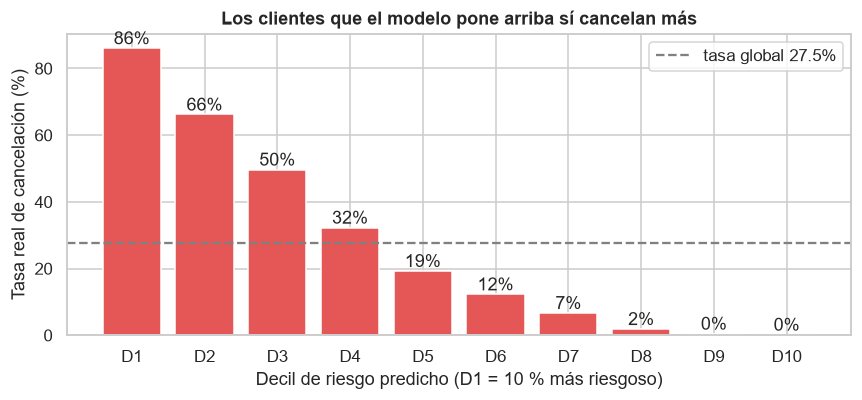

In [48]:
rk = pd.DataFrame({"proba": proba_test, "real": y_test.values})
rk["decil"] = pd.qcut(rk.proba.rank(method="first", ascending=False), 10, labels=[f"D{i}" for i in range(1, 11)])
dec = rk.groupby("decil", observed=True).agg(reservas=("real", "size"), canceladas=("real", "sum"), prob_media=("proba", "mean")).reset_index()
dec["tasa_real_%"] = (dec.canceladas / dec.reservas * 100).round(1); dec["lift"] = (dec.canceladas / dec.reservas / y_test.mean()).round(2)
dec["%_cancelaciones_acumulado"] = (dec.canceladas.cumsum() / dec.canceladas.sum() * 100).round(1)
display(dec.round(3))
fig, ax = plt.subplots(figsize=(8, 3.8)); ax.bar(dec.decil, dec["tasa_real_%"], color="#E45756"); ax.axhline(y_test.mean() * 100, color="gray", ls="--", label=f"tasa global {y_test.mean():.1%}")
ax.bar_label(ax.containers[0], fmt="%.0f%%"); ax.set_ylabel("Tasa real de cancelación (%)"); ax.set_xlabel("Decil de riesgo predicho (D1 = 10 % más riesgoso)"); ax.legend(); ax.set_title("Los clientes que el modelo pone arriba sí cancelan más", fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretación.** El 10 % de reservas con mayor probabilidad predicha se cancela en el 86,1 % de los casos (lift 3,1 sobre la tasa global de 27,5 %); los dos primeros deciles reúnen el 55,3 % de todas las cancelaciones y los tres primeros el 73,4 %. En los tres deciles de menor riesgo la tasa real es inferior al 2 %. Para el objetivo del negocio (identificar a los clientes con más posibilidades de cancelar) esto es lo que importa: revisando el 20–30 % de reservas de mayor puntuación se cubre la mayor parte del riesgo.

## 6.9 ¿Demasiado bueno para ser verdad?
AUC 0,894 no es sospechoso (en la literatura de este dataset los modelos de árboles llegan a 0,88–0,93 sin fuga). Aun así, antes de interpretar confirmamos el `assert` de fuga y, en la sección 7, aplicamos los tres métodos de detección, la demostración con variables prohibidas y las pruebas de drift.

In [49]:
assert not set(X_train.columns) & set(leakage_columns + post_event_columns)
print("Ninguna columna prohibida en X_train:", sorted(set(leakage_columns + post_event_columns)))

Ninguna columna prohibida en X_train: ['assigned_room_type', 'required_car_parking_spaces', 'reservation_status', 'reservation_status_date', 'room_changed']


## 6.10 Interpretación
### 6.10.1 Importancia por permutación (en test)
Caída del AUC al barajar cada variable; válida para cualquier modelo. Muestra de 8.000 filas de test y 5 repeticiones.

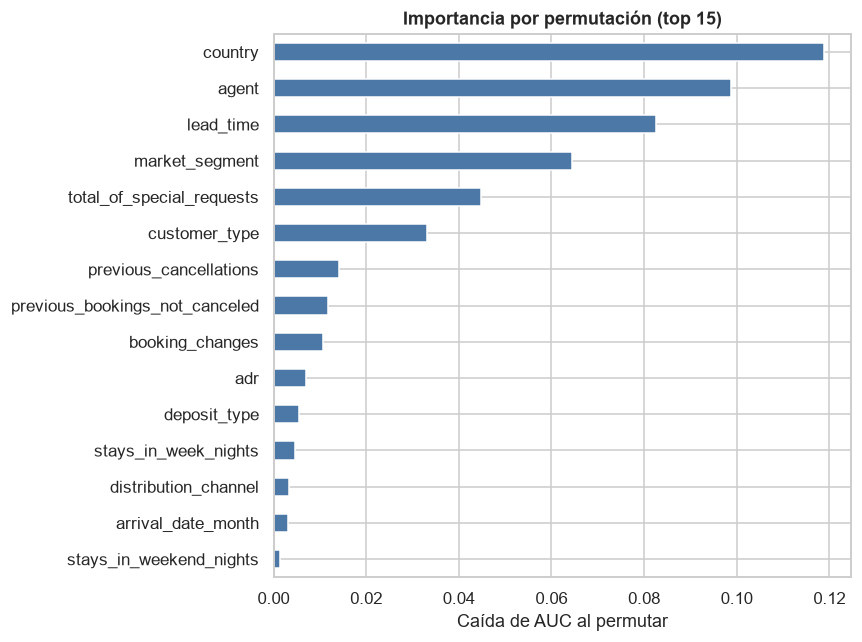

,caída_AUC
country,0.1188
agent,0.0987
lead_time,0.0827
market_segment,0.0644
total_of_special_requests,0.0447
customer_type,0.0331
previous_cancellations,0.0141
previous_bookings_not_canceled,0.0118
booking_changes,0.0106
adr,0.0071


In [50]:
Xt_s = X_test.sample(8000, random_state=RANDOM_STATE); yt_s = y_test.loc[Xt_s.index]
pi = permutation_importance(pipe_final, Xt_s, yt_s, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_perm = pd.Series(pi.importances_mean, index=features).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6)); imp_perm.head(15)[::-1].plot.barh(ax=ax, color="#4C78A8"); ax.set_xlabel("Caída de AUC al permutar"); ax.set_title("Importancia por permutación (top 15)", fontweight="bold"); plt.tight_layout(); plt.show()
display(imp_perm.round(4).head(10).to_frame("caída_AUC"))

**Interpretación.** Las variables que más pierde el modelo al barajar son `country` (−0,119), `agent` (−0,099), `lead_time` (−0,083), `market_segment` (−0,064) y `total_of_special_requests` (−0,045); luego `customer_type` (−0,033). Coincide con el EDA: origen, anticipación, canal y compromiso.

### 6.10.2 Coeficientes estandarizados de la regresión logística
El modelo lineal se usa como referencia interpretable: signo y magnitud de cada efecto *manteniendo lo demás fijo*. Advertencia: entre dummies del mismo grupo y numéricas relacionadas hay colinealidad; no interpretar coeficientes aislados.

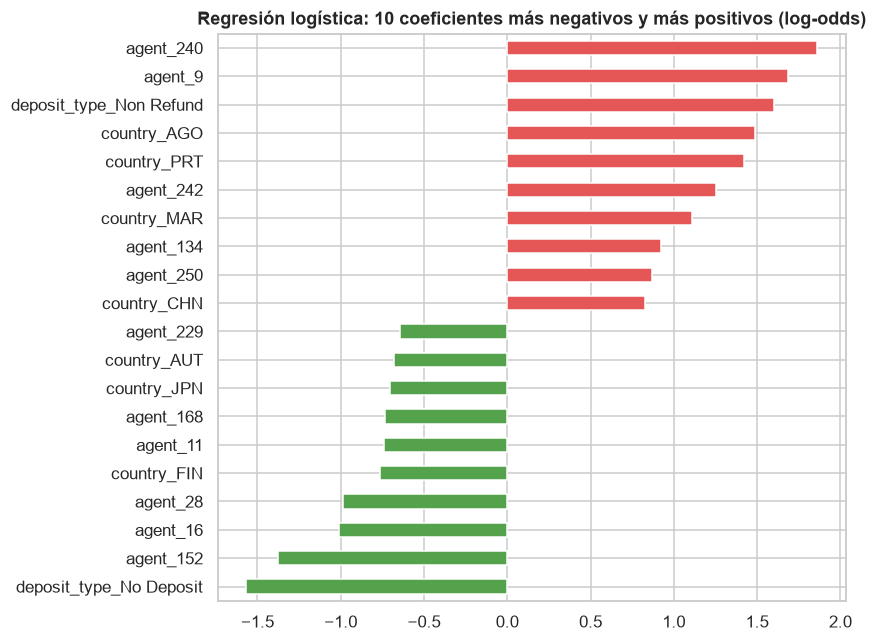

,más negativos (menos cancelación),más positivos (más cancelación)
0,deposit_type_No Deposit: -1.57,agent_240: +1.86
1,agent_152: -1.38,agent_9: +1.69
2,agent_16: -1.01,deposit_type_Non Refund: +1.60
3,agent_28: -0.99,country_AGO: +1.49
4,country_FIN: -0.77,country_PRT: +1.42
5,agent_11: -0.74,agent_242: +1.25
6,agent_168: -0.74,country_MAR: +1.11
7,country_JPN: -0.70,agent_134: +0.92


,total_of_special_requests,previous_bookings_not_canceled,booking_changes,is_repeated_guest,has_company,has_agent,days_in_waiting_list,babies,adults,children,stays_in_weekend_nights,adr,stays_in_week_nights,previous_cancellations,lead_time
coef_numéricas_estandarizadas,-0.63,-0.37,-0.26,-0.2,-0.16,-0.13,-0.05,-0.0,0.03,0.06,0.07,0.21,0.23,0.45,0.59


In [51]:
pipe_log = pipelines["Regresión logística"].fit(X_train, y_train)
nombres = pipe_log.named_steps["prep"].get_feature_names_out()
coef = pd.Series(pipe_log.named_steps["model"].coef_[0], index=[n.split("__", 1)[1] for n in nombres])
top = pd.concat([coef.sort_values().head(10), coef.sort_values().tail(10)])
fig, ax = plt.subplots(figsize=(8, 6)); top.plot.barh(ax=ax, color=["#54A24B" if v < 0 else "#E45756" for v in top]); ax.set_title("Regresión logística: 10 coeficientes más negativos y más positivos (log-odds)", fontweight="bold"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"más negativos (menos cancelación)": coef.sort_values().head(8).round(2).reset_index().apply(lambda r: f"{r['index']}: {r[0]:+.2f}", axis=1),
                      "más positivos (más cancelación)": coef.sort_values(ascending=False).head(8).round(2).reset_index().apply(lambda r: f"{r['index']}: {r[0]:+.2f}", axis=1)}))
display(coef[numeric_features].round(2).sort_values().to_frame("coef_numéricas_estandarizadas").T)

**Interpretación.** Entre las numéricas estandarizadas, los coeficientes positivos más grandes (más cancelación) son `lead_time` (+0,59) y `previous_cancellations` (+0,45); los negativos, `total_of_special_requests` (−0,63), `previous_bookings_not_canceled` (−0,37), `booking_changes` (−0,26) e `is_repeated_guest` (−0,20). Entre las dummies, `deposit_type_Non Refund` (+1,60) y `country_PRT` (+1,42) empujan hacia la cancelación y `deposit_type_No Deposit` (−1,57) en sentido contrario. Las dummies de `agent` (240: +1,86; 9: +1,69; 152: −1,38) tienen coeficientes grandes pero correlacionados con país y segmento (una agencia opera en pocos mercados), por eso la lectura robusta se hace por dimensiones.

### 6.10.3 Tabla por dimensiones de negocio
Suma de la importancia por permutación (truncada en 0) por dimensión: la tabla que responde la pregunta.

In [52]:
imp_dim = imp_perm.clip(lower=0).groupby(imp_perm.index.map(dimension)).sum().sort_values(ascending=False)
tabla_dimensiones = pd.DataFrame({"importancia": imp_dim.round(3), "%": (imp_dim / imp_dim.sum() * 100).round(1),
                                  "variables_top": [", ".join(imp_perm[[f for f in features if dimension[f] == d]].sort_values(ascending=False).head(2).index) for d in imp_dim.index]})
display(tabla_dimensiones)

,importancia,%,variables_top
Cliente,0.179,35.2,"country, customer_type"
Canal,0.168,32.9,"agent, market_segment"
Tiempo y anticipación,0.087,17.0,"lead_time, arrival_date_month"
Condiciones,0.068,13.3,"total_of_special_requests, booking_changes"
Hotel y estancia,0.008,1.6,"stays_in_week_nights, stays_in_weekend_nights"


### 6.10.4 ¿Necesitamos todas las variables?
CV (3 folds, submuestra de 30.000 filas de train) con subconjuntos de features.

In [53]:
X_s30 = X_train.sample(30000, random_state=RANDOM_STATE); y_s30 = y_train.loc[X_s30.index]
def auc_cv(cols, est=None, Xs=None, ys=None):
    Xs = X_s30 if Xs is None else Xs; ys = y_s30 if ys is None else ys
    est = HistGradientBoostingClassifier(random_state=RANDOM_STATE) if est is None else est
    pipe = Pipeline([("prep", crear_preprocesador("simple", None, subset_features=cols)), ("model", clone(est))])
    return cross_val_score(pipe, Xs[cols], ys, cv=cv3, scoring="roc_auc", n_jobs=-1).mean()
orden_perm = list(imp_perm.index)
subconjuntos = {"Todas (26)": features, "Top 6": orden_perm[:6], "Top 3": orden_perm[:3], "Sin country": [f for f in features if f != "country"],
                "Sin country ni agent": [f for f in features if f not in ("country", "agent")], "Solo lead_time": ["lead_time"]}
tabla_sub = pd.DataFrame([{"Subconjunto": k, "n_features": len(v), "AUC_CV": auc_cv(v)} for k, v in subconjuntos.items()])
display(tabla_sub.round(4))

,Subconjunto,n_features,AUC_CV
0,Todas (26),26,0.8818
1,Top 6,6,0.8628
2,Top 3,3,0.8193
3,Sin country,25,0.8213
4,Sin country ni agent,24,0.8079
5,Solo lead_time,1,0.6378


**Interpretación.** Con las 6 variables principales (país, agencia, anticipación, segmento, peticiones, tipo de cliente) el AUC es 0,863 frente a 0,882 con las 26: se conserva el 98 % del desempeño; con 3 cae a 0,819. Quitar solo `country` cuesta 0,06 (0,821) y quitar también `agent` deja 0,808: el modelo depende del *quién* y del *por dónde*, no solo del *cuándo*. `lead_time` sola ya supera al Dummy (0,638), pero el valor está en la combinación.

### 6.10.5 What-if: anticipación para una reserva representativa
Simulación **predictiva, no causal**: una reserva típica de City Hotel por Online TA, variando `lead_time` de 0 a 365 días, para un cliente de Portugal y uno de Reino Unido.

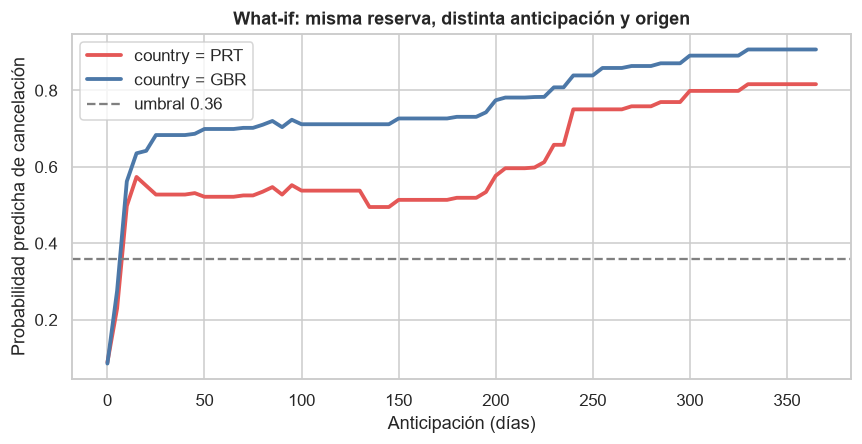

Reserva base: {'hotel': 'City Hotel', 'market_segment': 'Online TA', 'customer_type': 'Transient', 'deposit_type': 'No Deposit', 'adr': np.float64(98.64), 'total_of_special_requests': np.float64(0.0), 'agent': '9'}


In [54]:
base = X_train.mode().iloc[0].copy()
for c in numeric_features: base[c] = X_train[c].median()
base["hotel"], base["market_segment"], base["customer_type"] = "City Hotel", "Online TA", "Transient"
leads = np.arange(0, 366, 5)
fig, ax = plt.subplots(figsize=(8, 4.2))
for pais, color in [("PRT", "#E45756"), ("GBR", "#4C78A8")]:
    sim = pd.DataFrame([base] * len(leads)); sim["lead_time"] = leads; sim["country"] = pais
    sim = sim.astype(X_train.dtypes.to_dict())
    p = pipe_final.predict_proba(sim[features])[:, 1]; ax.plot(leads, p, lw=2.5, color=color, label=f"country = {pais}")
ax.axhline(t_f1, color="gray", ls="--", label=f"umbral {t_f1}"); ax.set_xlabel("Anticipación (días)"); ax.set_ylabel("Probabilidad predicha de cancelación"); ax.legend()
ax.set_title("What-if: misma reserva, distinta anticipación y origen", fontweight="bold"); plt.tight_layout(); plt.show()
print("Reserva base:", {k: base[k] for k in ["hotel", "market_segment", "customer_type", "deposit_type", "adr", "total_of_special_requests", "agent"]})

**Interpretación.** Para la misma reserva, la probabilidad predicha crece con la anticipación y la curva de Portugal está por encima de la de Reino Unido en todo el rango: el modelo reproduce la interacción del EDA (4.10). Es lo que el modelo *predice* si cambiara ese dato, no lo que pasaría si el hotel lo cambiara.

### 6.10.6 Efecto ajustado del hallazgo del EDA
Tasa cruda Portugal vs. otros (35,8 % vs 23,8 %) frente a la diferencia que el modelo mantiene **controlando** anticipación, canal, agencia y condiciones: predicción media en test fijando `country` = PRT vs. `country` = GBR para las mismas reservas.

In [55]:
Xcf = X_test.copy(); res_cf = {}
for pais in ["PRT", "GBR"]:
    Xcf["country"] = pais; res_cf[pais] = pipe_final.predict_proba(Xcf)[:, 1].mean()
brecha_cruda = dm.loc[X_test.index].groupby(dm.loc[X_test.index].country.eq("PRT")).is_canceled.mean()
print(f"Brecha cruda en test: PRT {brecha_cruda[True]:.1%} vs otros {brecha_cruda[False]:.1%} → {100*(brecha_cruda[True]-brecha_cruda[False]):.1f} pp")
print(f"Brecha ajustada (mismas reservas, solo cambia el país): PRT {res_cf['PRT']:.1%} vs GBR {res_cf['GBR']:.1%} → {100*(res_cf['PRT']-res_cf['GBR']):.1f} pp")

Brecha cruda en test: PRT 35.8% vs otros 23.7% → 12.2 pp
Brecha ajustada (mismas reservas, solo cambia el país): PRT 37.9% vs GBR 21.7% → 16.2 pp


**Interpretación.** La brecha cruda en test es de 12,2 pp (35,8 % vs 23,7 %) y la ajustada, con las mismas reservas y cambiando solo el país, de 16,2 pp (37,9 % vs 21,7 %): el efecto del origen **no** se explica por anticipación, canal o agencia; al contrario, al comparar contra Reino Unido (mercado especialmente estable) se amplía. Es asociación: el país no es accionable, pero sí la política de depósito o confirmación para ese mercado.

## 6.11 Respuesta a la pregunta de negocio
> *¿Qué características de la reserva, del cliente, del canal y de las condiciones están asociadas con la cancelación y cuáles tienen mayor capacidad de predecirla?*

In [56]:
veredicto = {"Cliente": "asociada: origen (PRT cancela más en todos los canales), historial de cancelaciones, tipo Transient",
             "Canal": "asociada: Online TA y la agencia concreta elevan el riesgo; directo/corporativo/con empresa lo reducen",
             "Tiempo y anticipación": "asociada: más anticipación → más cancelación (8 % → 40 %)",
             "Condiciones": "asociada: peticiones especiales y cambios reducen el riesgo; Non Refund lo eleva (pocas filas); tarifa alta lo eleva",
             "Hotel y estancia": "menor: City Hotel y estancias largas cancelan más, pero aportan poco controlando lo demás"}
display(tabla_dimensiones.assign(veredicto=[veredicto[d] for d in tabla_dimensiones.index]))

,importancia,%,variables_top,veredicto
Cliente,0.179,35.2,"country, customer_type",asociada: origen (PRT cancela más en todos los...
Canal,0.168,32.9,"agent, market_segment",asociada: Online TA y la agencia concreta elev...
Tiempo y anticipación,0.087,17.0,"lead_time, arrival_date_month",asociada: más anticipación → más cancelación (...
Condiciones,0.068,13.3,"total_of_special_requests, booking_changes",asociada: peticiones especiales y cambios redu...
Hotel y estancia,0.008,1.6,"stays_in_week_nights, stays_in_weekend_nights",menor: City Hotel y estancias largas cancelan ...


**Respuesta en una frase:** la cancelación está asociada, sobre todo, con *quién* reserva (origen y historial), *por dónde* (agencia online y agencia concreta) y *con cuánta anticipación*; las señales de compromiso (peticiones, cambios, cliente repetido) la reducen, y un modelo de Gradient Boosting con esas variables ordena el riesgo con AUC 0,89–0,90 en test y detecta tres de cada cuatro cancelaciones al umbral de máximo F1 (0,36 en el modelo base; 0,37 en el afinado de 7.5), concentrando el 86 % de cancelaciones reales en el decil más riesgoso.

**Recomendación operativa:** (1) puntuar cada reserva al crearse y revisar las que superen el umbral con más de 30 días de anticipación (confirmación activa, depósito o política de cancelación diferenciada), empezando por Online TA y el mercado doméstico; (2) usar la probabilidad para calibrar el overbooking por fecha en vez de una tasa fija; (3) incentivar señales de compromiso (peticiones, confirmaciones) que el modelo asocia a menor riesgo.

## 6.12 Conclusiones, limitaciones y siguientes pasos
**Limitaciones.** (1) Asociación, no causalidad: el modelo predice, no explica mecanismos. (2) Umbral 0,36 por validar con los costos reales de FP y FN. (3) Las filas duplicadas eliminadas podrían ser bloques reales; la prevalencia del dataset de trabajo (27,5 %) es menor que la cruda (37,0 %). (4) `booking_changes` y `days_in_waiting_list` se asumen disponibles al predecir. (5) Tendencia creciente de cancelación 2015→2017: el modelo debe reentrenarse periódicamente (ver 7.4). (6) Sin tuning exhaustivo todavía (7.5).

**Siguientes pasos.** Verificación de fuga y drift (sección 7), tuning, SHAP; después, evaluación de costo-beneficio del umbral con el área de revenue y una prueba piloto por canal.

# 7. Verificación: importancia, leakage, drift, tuning y SHAP

## Paso 1 — Mejor modelo base
Referencia fijada en 6.6: Gradient Boosting y Random Forest empatan (AUC CV 0,888 / 0,890); el ganador por parsimonia es Gradient Boosting. Ningún modelo toca test en los pasos 2–4.

## Paso 2 — Las tres caras de la importancia
Impureza (Random Forest), permutación (ya calculada) y |coeficientes| de la logística, agregadas por variable original.

In [57]:
rf_pipe = Pipeline([("prep", crear_preprocesador("simple", None)), ("model", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE))]).fit(X_s30, y_s30)
nombres_rf = rf_pipe.named_steps["prep"].get_feature_names_out()
def variable_original(nombre):
    col = nombre.split("__", 1)[1]
    return next((f for f in sorted(features, key=len, reverse=True) if col == f or col.startswith(f + "_")), col)
imp_imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=[variable_original(n) for n in nombres_rf]).groupby(level=0).sum().sort_values(ascending=False)
imp_coef = coef.abs().groupby(coef.index.map(lambda c: next((f for f in sorted(features, key=len, reverse=True) if c == f or c.startswith(f + "_")), c))).sum().sort_values(ascending=False)
tres = pd.DataFrame({"Impureza (RF)": imp_imp.head(5).index, "Permutación (HGB)": imp_perm.head(5).index, "|Coef| (logística)": imp_coef.head(5).index}, index=[f"top {i}" for i in range(1, 6)])
display(tres)
print("En el top-3 de los tres métodos:", set(imp_imp.head(3).index) & set(imp_perm.head(3).index) & set(imp_coef.head(3).index))

,Impureza (RF),Permutación (HGB),|Coef| (logística)
top 1,lead_time,country,agent
top 2,country,agent,country
top 3,adr,lead_time,deposit_type
top 4,arrival_date_month,market_segment,market_segment
top 5,arrival_dow,total_of_special_requests,reserved_room_type


En el top-3 de los tres métodos: {'country'}


**Interpretación.** La impureza pone arriba `lead_time`, `adr`, `arrival_date_month` y `arrival_dow`: continuas o con muchas categorías, que acumulan divisiones aunque aporten poco desempeño (`adr` y el día de semana apenas pesan en permutación). Es su sesgo conocido. La permutación mide desempeño y la logística contribución lineal; esta última destaca `deposit_type` (coeficiente grande de *Non Refund* para pocas filas). `country` está en el top-3 de los tres métodos y `agent`, `lead_time` y `market_segment` en el top-5 de al menos dos: evidencia robusta.

## Paso 3 — Leakage y drift

### 3.1 Cinco causas por construcción

| Causa | Qué revisar | Qué se hizo |
|---|---|---|
| Partir aleatoriamente datos temporales | Partición por tiempo | 3.4: entrenar 2015–2016, probar 2017 |
| Procesar antes de partir | Imputación / escalado / One-Hot dentro del pipeline | `Pipeline` + `ColumnTransformer` ajustados solo con train |
| Duplicados entre train y test | Deduplicar antes de partir | 31.994 filas idénticas eliminadas en 2.0; abajo se mide cuánto inflaban |
| Group leakage | Filas de un mismo grupo en ambos lados | No hay ID de cliente ni de pedido; el riesgo residual son reservas casi idénticas (bloques) y se acota con la partición temporal |
| Fuga desde la generación del dato | Columnas rellenadas después del evento | `reservation_status*`, `assigned_room_type`, `required_car_parking_spaces` excluidas |

**Demostración de la causa 3:** mismo modelo, dataset crudo (con duplicados) y split aleatorio.

In [58]:
raw = df.copy(); raw = raw[(raw.adults + raw.children.fillna(0) + raw.babies) > 0].copy()
raw.loc[(raw.adr < 0) | (raw.adr > 1000), "adr"] = np.nan; raw["children"] = raw.children.fillna(0).astype(int); raw["country"] = raw.country.fillna("Unknown")
raw["has_agent"] = raw.agent.notna().astype(int); raw["has_company"] = raw.company.notna().astype(int)
raw["agent"] = raw.agent.fillna(0).astype(int).astype(str).replace({"0": "SinAgencia"}); raw["meal"] = raw.meal.replace({"Undefined": "SC"})
raw["arrival_dow"] = pd.to_datetime(raw.arrival_date_year.astype(str) + "-" + raw.arrival_date_month + "-" + raw.arrival_date_day_of_month.astype(str), format="%Y-%B-%d").dt.day_name()
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(raw[features], raw.is_canceled, test_size=0.25, stratify=raw.is_canceled, random_state=RANDOM_STATE)
pipe_raw = Pipeline([("prep", crear_preprocesador("simple", None)), ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(Xr_tr, yr_tr)
pr = pipe_raw.predict_proba(Xr_te)[:, 1]
firmas_train = set(map(tuple, Xr_tr.values)); copia_en_train = np.array([tuple(r) in firmas_train for r in Xr_te.values])
print(f"Crudo con duplicados: AUC {roc_auc_score(yr_te, pr):.4f} | PR-AUC {average_precision_score(yr_te, pr):.4f} | F1@0,5 {f1_score(yr_te, pr >= 0.5):.4f}  (deduplicado: AUC {auc_test:.4f})")
print(f"Filas de test con copia idéntica en train: {copia_en_train.sum():,} de {len(Xr_te):,} → AUC en esas filas {roc_auc_score(yr_te[copia_en_train], pr[copia_en_train]):.4f}; en el resto {roc_auc_score(yr_te[~copia_en_train], pr[~copia_en_train]):.4f}")

Crudo con duplicados: AUC 0.9356 | PR-AUC 0.9087 | F1@0,5 0.8044  (deduplicado: AUC 0.8940)
Filas de test con copia idéntica en train: 9,868 de 29,803 → AUC en esas filas 0.9829; en el resto 0.8837


**Interpretación.** Con los duplicados el AUC "sube" a 0,936 y el F1 a 0,80, pero 9.868 de las 29.803 filas de test (un tercio) tienen una copia idéntica en train y en ellas el modelo acierta casi siempre (AUC 0,983); en las filas sin copia el AUC es 0,884, el mismo nivel que el dataset deduplicado. La mejora era memorización: la deduplicación fue correcta.

### 3.2 Tres métodos de detección (CV 3 folds, 30.000 filas de train)
1. **Variable sola**: AUC de un modelo con una única feature. 2. **Ablación**: caída al quitar cada feature. 3. **Curva acumulada**: añadir features por orden de importancia.

In [59]:
t0 = time.time()
solo = pd.Series({c: auc_cv([c]) for c in features}).sort_values(ascending=False)
auc_full = auc_cv(features)
ablacion = pd.Series({c: auc_cv([f for f in features if f != c]) - auc_full for c in features}).sort_values()
display(pd.DataFrame({"AUC_sola": solo.round(4).head(10), "ablación_(caída)": ablacion.round(4).reindex(solo.head(10).index)}))
print(f"AUC con todas: {auc_full:.4f} | 10 ablaciones más costosas:", ablacion.round(4).head(10).to_dict(), f"| {time.time()-t0:.0f} s")

,AUC_sola,ablación_(caída)
agent,0.6581,-0.0198
lead_time,0.6378,-0.0215
market_segment,0.6188,0.0002
adr,0.6112,-0.0016
country,0.6076,-0.0605
total_of_special_requests,0.5741,-0.0229
distribution_channel,0.5676,-0.0002
stays_in_week_nights,0.5618,0.0001
arrival_date_month,0.5565,-0.0007
booking_changes,0.5557,-0.0035


AUC con todas: 0.8818 | 10 ablaciones más costosas: {'country': -0.0605, 'total_of_special_requests': -0.0229, 'lead_time': -0.0215, 'agent': -0.0198, 'customer_type': -0.0066, 'previous_cancellations': -0.0046, 'booking_changes': -0.0035, 'adr': -0.0016, 'previous_bookings_not_canceled': -0.0008, 'arrival_date_month': -0.0007} | 56 s


**Interpretación.** Ninguna variable sola se acerca a 1,0: la mejor es `agent` (0,66) seguida de `lead_time` (0,64). Sin fuga por variable única. En ablación la mayor caída es `country` (−0,06), después `total_of_special_requests`, `lead_time` y `agent` (−0,02 cada una); el resto ≈ 0: el modelo se apoya en pocas variables y ninguna lo "resuelve" sola.

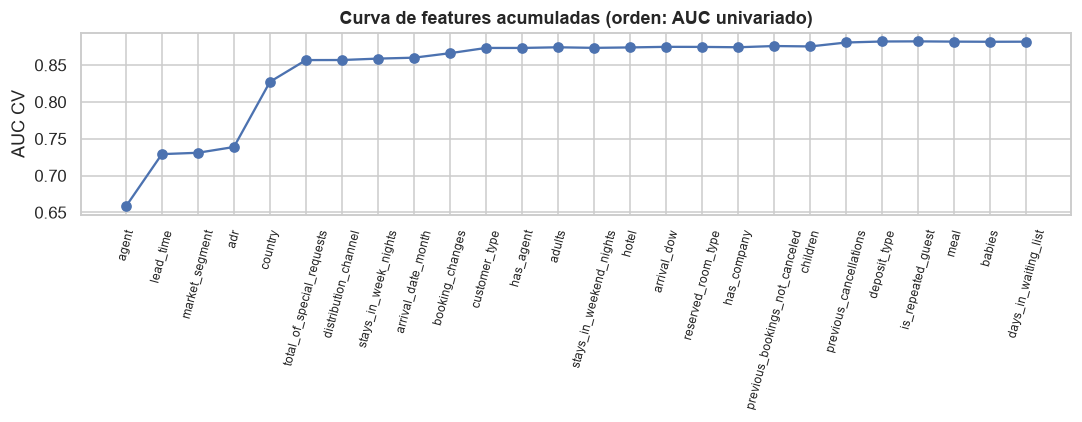

,k,variable_añadida,AUC_CV
0,1,agent,0.6581
1,2,lead_time,0.7292
2,3,market_segment,0.7310
3,4,adr,0.7389
4,5,country,0.8273
5,6,total_of_special_requests,0.8568
6,7,distribution_channel,0.8569
7,8,stays_in_week_nights,0.8588


In [60]:
orden = list(solo.index)
curva = pd.DataFrame([{"k": k, "variable_añadida": orden[k - 1], "AUC_CV": auc_cv(orden[:k])} for k in range(1, len(orden) + 1)])
fig, ax = plt.subplots(figsize=(10, 4)); ax.plot(curva.k, curva.AUC_CV, marker="o"); ax.set_xticks(curva.k); ax.set_xticklabels(curva.variable_añadida, rotation=75, fontsize=8)
ax.set_ylabel("AUC CV"); ax.set_title("Curva de features acumuladas (orden: AUC univariado)", fontweight="bold"); plt.tight_layout(); plt.show()
display(curva.round(4).head(8))

**Interpretación.** Los escalones más grandes son `lead_time` (0,658 → 0,729) y `country` (0,739 → 0,827), seguidos de `total_of_special_requests` (→ 0,857); desde la séptima variable la curva se aplana en 0,86–0,88. Ningún escalón acerca el modelo a 1,0, que es lo que haría una feature filtrada; los saltos corresponden a las variables que el EDA ya identificó como principales.

**Contraste con las prohibidas** (solo para mostrar cómo se vería la fuga):

In [61]:
dd30 = dm.loc[X_s30.index]
print("reservation_status sola → AUC", round(cross_val_score(Pipeline([("oh", OneHotEncoder(handle_unknown="ignore")), ("m", LogisticRegression())]), dd30[["reservation_status"]], y_s30, cv=cv3, scoring="roc_auc").mean(), 4))
for c in ["room_changed", "required_car_parking_spaces"]:
    print(f"{c} sola → AUC", round(cross_val_score(HistGradientBoostingClassifier(random_state=RANDOM_STATE), dd30[[c]], y_s30, cv=cv3, scoring="roc_auc").mean(), 4))
prep_plus = ColumnTransformer([("post", "passthrough", ["required_car_parking_spaces", "room_changed"])], remainder=crear_preprocesador("simple", None))
auc_plus = cross_val_score(Pipeline([("prep", prep_plus), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]), dd30[features + ["required_car_parking_spaces", "room_changed"]], y_s30, cv=cv3, scoring="roc_auc").mean()
print(f"Todas + parqueo + cambio de habitación → AUC {auc_plus:.4f} (vs {auc_full:.4f} sin ellas)")

reservation_status sola → AUC 1.0


room_changed sola → AUC 0.5846


required_car_parking_spaces sola → AUC 0.5598


Todas + parqueo + cambio de habitación → AUC 0.9054 (vs 0.8818 sin ellas)


**Conclusión escrita.** `reservation_status` sola da AUC 1,0: es el target. El parqueo y el cambio de habitación solos dan 0,56–0,58 (parecen inocuos) pero añadidos al modelo completo lo suben de 0,882 a 0,905 (+0,024): una señal perfecta en una dirección (0 cancelaciones con parqueo) que no está disponible al reservar. **No hay leakage en el modelo final; el desempeño (0,89) es estructura del negocio** (anticipación × origen × canal) y queda muy lejos de lo que produciría una variable filtrada.

### 3.3 Drift
PSI por variable entre llegadas 2015–2016 (antiguo) y 2017 (reciente), incluido el target; validación adversarial train vs. test.

In [62]:
sys.path.insert(0, "tools")   # tools/psi_drift.py: PSI por variable entre dos periodos
from psi_drift import psi_tabla, categorias_que_cambian
tabla_psi = psi_tabla(dm, "arrival_date_year", [2015, 2016], [2017], columnas=features + ["is_canceled"])
display(tabla_psi.head(10))
print("Meses presentes por año:", dm.groupby("arrival_date_year").arrival_date_month.nunique().to_dict())
top_ag = dm.agent.value_counts().head(6).index
display((pd.crosstab(dm.arrival_date_year, dm.agent.where(dm.agent.isin(top_ag), "otras"), normalize="index") * 100).round(1))
Xa = pd.concat([X_train, X_test]); ya = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
auc_adv = cross_val_score(Pipeline([("prep", crear_preprocesador("simple", None)), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]), Xa, ya, cv=cv3, scoring="roc_auc", n_jobs=-1).mean()
print(f"Validación adversarial train vs test: AUC {auc_adv:.4f} (≈ 0,5 ⇒ misma distribución)")

,Variable,PSI,Nivel
0,arrival_date_month,5.2261,FUERTE
1,agent,0.5796,FUERTE
2,adr,0.1399,moderado
3,country,0.1067,moderado
4,lead_time,0.0678,estable
5,market_segment,0.0529,estable
6,customer_type,0.0509,estable
7,meal,0.0363,estable
8,is_canceled,0.0237,estable
9,reserved_room_type,0.0228,estable


Meses presentes por año: {2015: 6, 2016: 12, 2017: 8}


agent,14,240,250,7,9,SinAgencia,otras
arrival_date_year,,,,,,,
2015,2.6,18.3,3.4,2.4,15.9,17.5,39.8
2016,3.4,14.1,2.8,3.9,34.9,14.3,26.5
2017,4.9,14.6,3.6,4.2,37.4,11.9,23.4


Validación adversarial train vs test: AUC 0.5005 (≈ 0,5 ⇒ misma distribución)


**Interpretación.** El PSI de `arrival_date_month` es enorme por construcción (2017 solo tiene enero–agosto: cambio de cobertura, no de comportamiento). El drift real está en `agent` (PSI 0,58: la agencia 9 pasa del 15,9 % de las reservas en 2015 al 37,4 % en 2017, mientras las reservas sin agencia bajan de 17,5 % a 11,9 %) y, moderado, en `adr` (0,14, tarifas que suben) y `country` (0,11). El target es estable (0,02) y la validación adversarial da 0,50: el split aleatorio train/test es representativo, pero el **futuro** no se parece al pasado en canal y precio.

### 3.4 Partición temporal
Entrenar con llegadas 2015–2016 y probar con 2017 (31.633 reservas). Variantes sin `agent` y sin `agent` ni `country` para medir cuánto del deterioro viene de las variables con drift.

In [63]:
mask = dm.arrival_date_year <= 2016
res_t = []
for nombre, cols in [("Todas", features), ("Sin agent", [f for f in features if f != "agent"]), ("Sin agent ni country", [f for f in features if f not in ("agent", "country")])]:
    pt = Pipeline([("prep", crear_preprocesador("simple", None, subset_features=cols)), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(X_all.loc[mask, cols], y_all[mask])
    pp = pt.predict_proba(X_all.loc[~mask, cols])[:, 1]
    res_t.append({"Features": nombre, "AUC_2017": roc_auc_score(y_all[~mask], pp), "PR_AUC_2017": average_precision_score(y_all[~mask], pp), "F1@0,5": f1_score(y_all[~mask], pp >= 0.5)})
display(pd.DataFrame(res_t).round(4))
print(f"Referencia con split aleatorio: AUC test {auc_test:.4f}")

,Features,AUC_2017,PR_AUC_2017,"F1@0,5"
0,Todas,0.8368,0.6922,0.5664
1,Sin agent,0.8029,0.6482,0.5299
2,Sin agent ni country,0.7806,0.6267,0.5066


Referencia con split aleatorio: AUC test 0.8940


**Interpretación.** Al predecir 2017 con lo aprendido en 2015–2016 el AUC baja de 0,894 (split aleatorio) a 0,837 y el F1 a 0,57: hay **drift temporal real**, coherente con la tendencia creciente de cancelación. Quitar las variables con drift no lo arregla, lo empeora (sin `agent` 0,803; sin `agent` ni `country` 0,781): la agencia y el país siguen siendo informativos en 2017; lo que cambia es la tasa base y el peso de cada canal. Implicación: el modelo debe reentrenarse con ventana móvil (p. ej. cada trimestre) y la métrica honesta para producción es la temporal (≈ 0,84), no la aleatoria (0,89).

## Paso 4 — Tuning con Optuna (Gradient Boosting)
20 trials, CV 3 folds sobre una submuestra de 20.000 filas de train, objetivo ROC-AUC.

In [64]:
import optuna; from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)
X_s20 = X_train.sample(20000, random_state=RANDOM_STATE); y_s20 = y_train.loc[X_s20.index]
def objetivo(trial):
    params = dict(learning_rate=trial.suggest_float("learning_rate", 0.02, 0.3, log=True), max_iter=trial.suggest_int("max_iter", 100, 600),
                  max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 64), l2_regularization=trial.suggest_float("l2_regularization", 0.0, 1.0),
                  min_samples_leaf=trial.suggest_int("min_samples_leaf", 10, 100), random_state=RANDOM_STATE)
    pipe = Pipeline([("prep", crear_preprocesador("simple", None)), ("m", HistGradientBoostingClassifier(**params))])
    return cross_val_score(pipe, X_s20, y_s20, cv=cv3, scoring="roc_auc", n_jobs=-1).mean()
t0 = time.time()
study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_STATE)); study.optimize(objetivo, n_trials=20)
auc_default_20k = cross_val_score(Pipeline([("prep", crear_preprocesador("simple", None)), ("m", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]), X_s20, y_s20, cv=cv3, scoring="roc_auc", n_jobs=-1).mean()
print(f"HGB por defecto (misma submuestra): {auc_default_20k:.4f} | mejor Optuna: {study.best_value:.4f} | {time.time()-t0:.0f} s")
print("Mejores parámetros:", {k: round(v, 4) if isinstance(v, float) else v for k, v in study.best_params.items()})
print("Importancia de hiperparámetros:", {k: round(v, 3) for k, v in optuna.importance.get_param_importances(study).items()})

HGB por defecto (misma submuestra): 0.8776 | mejor Optuna: 0.8787 | 59 s
Mejores parámetros: {'learning_rate': 0.0478, 'max_iter': 501, 'max_leaf_nodes': 48, 'l2_regularization': 0.0541, 'min_samples_leaf': 11}
Importancia de hiperparámetros: {'max_iter': 0.684, 'min_samples_leaf': 0.175, 'max_leaf_nodes': 0.066, 'l2_regularization': 0.064, 'learning_rate': 0.01}


**Interpretación.** En la submuestra Optuna mejora el AUC en +0,001 (0,878 → 0,879): el hiperparámetro que importa es `max_iter` (68 %: más árboles, con tasa de aprendizaje baja), seguido de `min_samples_leaf`. El techo del problema está dado por la información disponible, no por los hiperparámetros; el valor de Optuna es demostrar que ese techo existe y dónde está.

## Paso 5 — Modelo final y test único
CV 5 folds sobre **todo train** con el afinado frente a la referencia. Regla fijada de antemano: si queda dentro de ±0,002 del por defecto, el modelo final es el por defecto (parsimonia) y la evaluación de 6.7 es la única; si lo supera por más, el afinado pasa a ser el modelo final y se evalúa en test una sola vez.

In [65]:
pipe_tuned = Pipeline([("prep", clone(preprocesador)), ("model", HistGradientBoostingClassifier(**study.best_params, random_state=RANDOM_STATE))])
r_tuned = evaluar_cv(pipe_tuned, X_train, y_train, cv5)
comparacion = pd.concat([tabla_modelos[tabla_modelos.Modelo.isin(["Regresión logística", "Random Forest", "Gradient Boosting"])], pd.DataFrame([{"Modelo": "Gradient Boosting afinado", **r_tuned}])]).sort_values("AUC_CV", ascending=False)
display(comparacion.round(4))
dentro = abs(r_tuned["AUC_CV"] - tabla_modelos.set_index("Modelo").loc["Gradient Boosting", "AUC_CV"]) <= 0.002
print("¿Afinado dentro de ±0,002 del por defecto?", dentro, "→ modelo final:", "Gradient Boosting por defecto (ya evaluado en test en 6.7)" if dentro else "Gradient Boosting afinado (se evalúa en test una sola vez)")

,Modelo,AUC_CV,AUC_std,PR_AUC_CV,Tiempo_s
0,Gradient Boosting afinado,0.8911,0.0020,0.7646,20.0976
4,Random Forest,0.8899,0.0026,0.7629,19.0449
5,Gradient Boosting,0.8879,0.0021,0.7592,7.6013
1,Regresión logística,0.8292,0.0028,0.6485,2.7478


¿Afinado dentro de ±0,002 del por defecto? False → modelo final: Gradient Boosting afinado (se evalúa en test una sola vez)


**Decisión.** El afinado alcanza AUC CV 0,891 frente a 0,888 del por defecto (+0,003, fuera del margen de ±0,002) y supera también a Random Forest (0,890). Por la regla fijada, **el modelo final es el Gradient Boosting afinado** (learning_rate 0,048, 501 iteraciones, 48 hojas, min_samples_leaf 11). Se evalúa en test una sola vez; la cifra de 6.7 (0,894) fue el reporte del modelo base, no un criterio de selección.

In [66]:
pipe_final = pipe_tuned.fit(X_train, y_train)
proba_test = pipe_final.predict_proba(X_test)[:, 1]
auc_test_final, ap_test_final = roc_auc_score(y_test, proba_test), average_precision_score(y_test, proba_test)
tabla_u = pd.DataFrame([{"umbral": round(t, 2), "precision": precision_score(y_test, proba_test >= t, zero_division=0), "recall": recall_score(y_test, proba_test >= t), "f1": f1_score(y_test, proba_test >= t)} for t in umbrales])
t_f1 = tabla_u.loc[tabla_u.f1.idxmax(), "umbral"]; t_rec80 = tabla_u[tabla_u.recall >= 0.80].umbral.max()
tn, fp, fn, tp = confusion_matrix(y_test, proba_test >= t_f1).ravel()
print(f"MODELO FINAL (afinado) en test: ROC-AUC {auc_test_final:.4f} | PR-AUC {ap_test_final:.4f} | (base: {auc_test:.4f} / {ap_test:.4f})")
print(f"Umbral máx F1 = {t_f1}: F1 {tabla_u.f1.max():.3f}, precision {tp/(tp+fp):.3f}, recall {tp/(tp+fn):.3f} → TP {tp:,} FN {fn:,} FP {fp:,} TN {tn:,} | umbral recall ≥ 80 %: {t_rec80}")
rk = pd.DataFrame({"proba": proba_test, "real": y_test.values}); rk["decil"] = pd.qcut(rk.proba.rank(method="first", ascending=False), 10, labels=[f"D{i}" for i in range(1, 11)])
dec = rk.groupby("decil", observed=True).agg(reservas=("real", "size"), canceladas=("real", "sum")).reset_index(); dec["tasa_real_%"] = (dec.canceladas / dec.reservas * 100).round(1)
dec["lift"] = (dec.canceladas / dec.reservas / y_test.mean()).round(2); dec["%_cancelaciones_acumulado"] = (dec.canceladas.cumsum() / dec.canceladas.sum() * 100).round(1)
display(dec.head(4))

MODELO FINAL (afinado) en test: ROC-AUC 0.8976 | PR-AUC 0.7770 | (base: 0.8940 / 0.7685)
Umbral máx F1 = 0.37: F1 0.710, precision 0.674, recall 0.749 → TP 4,495 FN 1,507 FP 2,173 TN 13,633 | umbral recall ≥ 80 %: 0.31


,decil,reservas,canceladas,tasa_real_%,lift,%_cancelaciones_acumulado
0,D1,2181,1902,87.2,3.17,31.7
1,D2,2181,1457,66.8,2.43,56.0
2,D3,2181,1082,49.6,1.80,74.0
3,D4,2180,691,31.7,1.15,85.5


**Interpretación.** El modelo final alcanza en test ROC-AUC 0,898 y PR-AUC 0,777 (base: 0,894 / 0,769). Al umbral de máximo F1 (0,37) detecta 4.495 de 6.002 cancelaciones (recall 75 %) con 2.173 falsas alarmas (precision 67 %, F1 0,710); con 0,31 el recall llega al 80 %. El decil de mayor riesgo se cancela en el 87,2 % de los casos (lift 3,2) y los dos primeros deciles reúnen el 56 % de las cancelaciones. Estas son las cifras que van a la presentación y al traspaso.

### Artefacto del modelo final
Guardamos el pipeline completo (preprocesador + modelo) y su metadata para poder puntuar reservas nuevas fuera del notebook (lo usará el despliegue planteado en `Despliegue_FastAPI.ipynb`).

In [67]:
import joblib, json
Path("models").mkdir(exist_ok=True)
joblib.dump(pipe_final, "models/modelo_cancelacion.joblib")
metadata = {"modelo": "HistGradientBoostingClassifier afinado con Optuna", "fecha": pd.Timestamp.today().strftime("%Y-%m-%d"),
            "features": features, "numeric_features": numeric_features, "nominal_features": nominal_features,
            "prohibidas": leakage_columns + post_event_columns, "hiperparametros": study.best_params,
            "metricas_test": {"roc_auc": round(float(auc_test_final), 4), "pr_auc": round(float(ap_test_final), 4), "umbral_max_f1": float(t_f1),
                              "f1": round(float(tabla_u.f1.max()), 4), "umbral_recall_80": float(t_rec80)},
            "prevalencia_train": round(float(y_train.mean()), 4), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
            "ejemplos_categorias": {c: sorted(X_train[c].astype(str).unique().tolist())[:12] for c in nominal_features}}
json.dump(metadata, open("models/metadata.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("Guardado models/modelo_cancelacion.joblib y models/metadata.json |", Path("models/modelo_cancelacion.joblib").stat().st_size // 1024, "KB")

Guardado models/modelo_cancelacion.joblib y models/metadata.json | 2409 KB


## Paso 6 — SHAP
`TreeExplainer` sobre el pipeline final (afinado), muestra de 1.000 filas de test, en log-odds. Global (agregado por variable original), dependencia de `lead_time` y dos casos individuales.

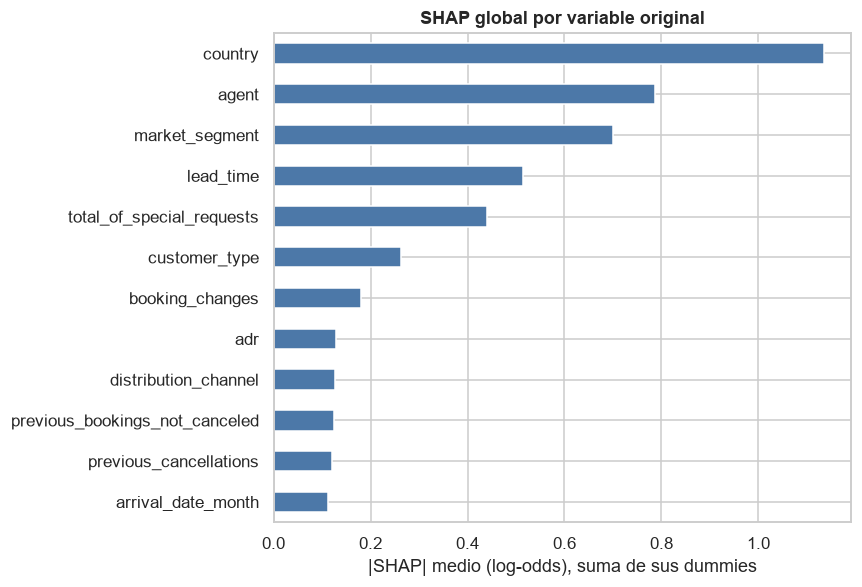

,SHAP_global,permutación
country,1.135,0.1188
agent,0.787,0.0987
market_segment,0.700,0.0644
lead_time,0.515,0.0827
total_of_special_requests,0.440,0.0447
customer_type,0.264,0.0331
booking_changes,0.180,0.0106
adr,0.129,0.0071


In [68]:
import shap
prep_f = pipe_final.named_steps["prep"]; modelo_f = pipe_final.named_steps["model"]
X_shap = X_test.sample(1000, random_state=RANDOM_STATE)
Xs_t = prep_f.transform(X_shap); nombres_f = [n.split("__", 1)[1] for n in prep_f.get_feature_names_out()]
sv = shap.TreeExplainer(modelo_f)(Xs_t); sv.feature_names = nombres_f
agg = pd.Series(np.abs(sv.values).mean(0), index=nombres_f)
agg_var = agg.groupby(agg.index.map(lambda c: next((f for f in sorted(features, key=len, reverse=True) if c == f or c.startswith(f + "_")), c))).sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5)); agg_var.head(12)[::-1].plot.barh(ax=ax, color="#4C78A8"); ax.set_xlabel("|SHAP| medio (log-odds), suma de sus dummies"); ax.set_title("SHAP global por variable original", fontweight="bold"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"SHAP_global": agg_var.round(3).head(8), "permutación": imp_perm.round(4).reindex(agg_var.head(8).index)}))

**Interpretación.** SHAP y permutación coinciden en el top: `country`, `agent`, `market_segment`, `lead_time` y `total_of_special_requests`. SHAP suma la contribución de todas las dummies de una variable (por eso `country` y `agent`, con decenas de columnas, pesan más) y refleja cuánto mueve cada variable la predicción; la permutación mide cuánto desempeño se pierde. No es contradicción: son dos preguntas distintas con la misma respuesta.

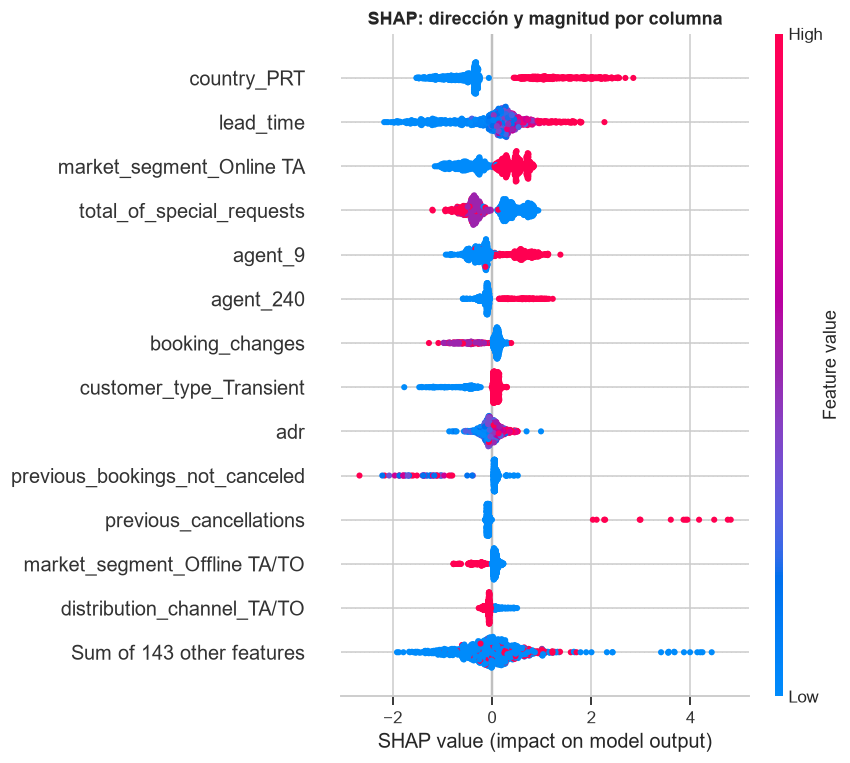

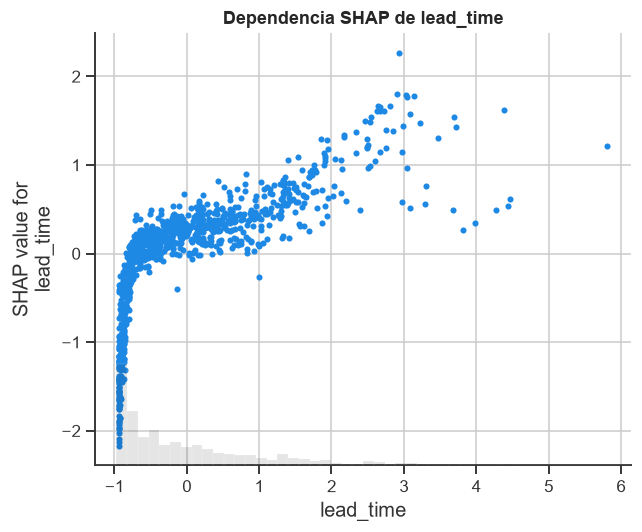

In [69]:
shap.plots.beeswarm(sv, max_display=14, show=False); plt.title("SHAP: dirección y magnitud por columna", fontweight="bold"); plt.tight_layout(); plt.show()
shap.plots.scatter(sv[:, "lead_time"], show=False); plt.title("Dependencia SHAP de lead_time", fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretación.** En el beeswarm, valores altos de `lead_time` (rojo) empujan hacia la cancelación y valores altos de `total_of_special_requests` o `booking_changes` empujan hacia la no cancelación; `country_PRT = 1` sube el riesgo. La dependencia de `lead_time` crece rápido en los primeros 30–60 días y se aplana después, coherente con la tabla por rangos del EDA (4.4).


Reserva de mayor riesgo predicho: probabilidad 0.999 | real: cancelada
{'hotel': 'City Hotel', 'country': 'PRT', 'market_segment': 'Groups', 'agent': '1', 'lead_time': 398, 'deposit_type': 'Non Refund', 'total_of_special_requests': 0, 'previous_cancellations': 0, 'customer_type': 'Transient'}


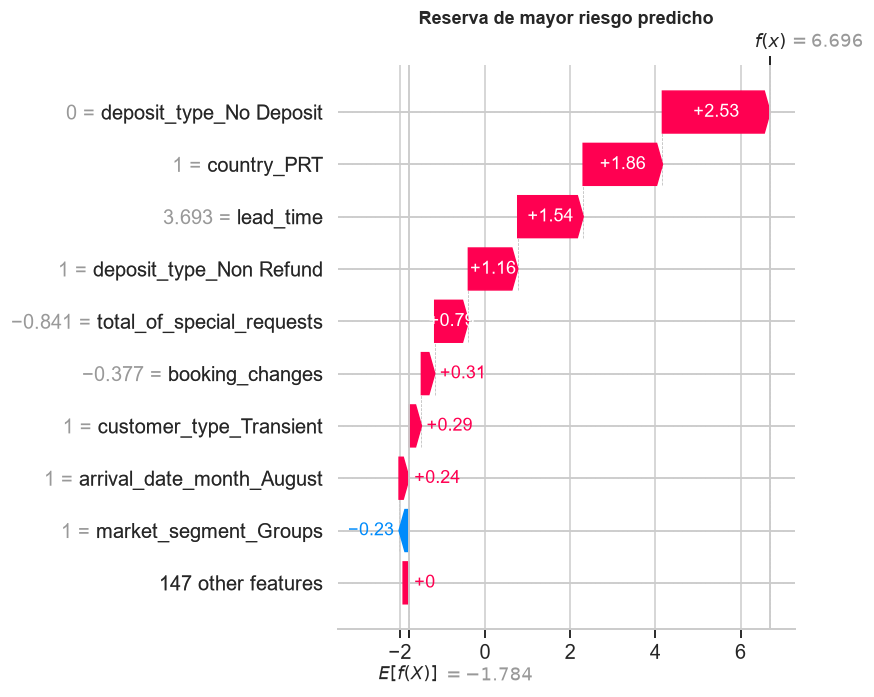


Reserva de menor riesgo predicho: probabilidad 0.001 | real: no cancelada
{'hotel': 'City Hotel', 'country': 'DEU', 'market_segment': 'Offline TA/TO', 'agent': '28', 'lead_time': 52, 'deposit_type': 'No Deposit', 'total_of_special_requests': 0, 'previous_cancellations': 0, 'customer_type': 'Transient'}


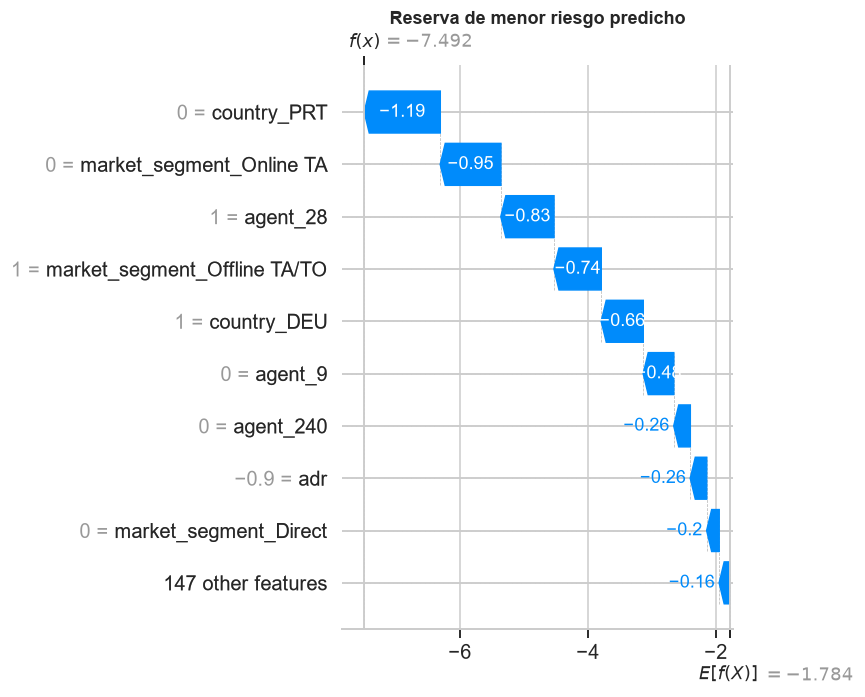

In [70]:
i_max, i_min = sv.values.sum(1).argmax(), sv.values.sum(1).argmin()
for i, titulo in [(i_max, "Reserva de mayor riesgo predicho"), (i_min, "Reserva de menor riesgo predicho")]:
    print(f"\n{titulo}: probabilidad {modelo_f.predict_proba(Xs_t[[i]])[0, 1]:.3f} | real: {'cancelada' if y_test.loc[X_shap.index[i]] == 1 else 'no cancelada'}")
    print(X_shap.iloc[i][["hotel", "country", "market_segment", "agent", "lead_time", "deposit_type", "total_of_special_requests", "previous_cancellations", "customer_type"]].to_dict())
    shap.plots.waterfall(sv[i], max_display=10, show=False); plt.title(titulo, fontweight="bold"); plt.tight_layout(); plt.show()

**Interpretación.** Los dos waterfalls muestran la descomposición individual. La reserva de mayor riesgo (probabilidad 0,999, y sí se canceló) reúne origen Portugal, segmento *Groups* con la agencia 1, depósito *Non Refund*, 398 días de anticipación y cero peticiones. La de menor riesgo (0,001, no cancelada) es un cliente alemán vía operador tradicional (agencia 28), sin depósito y con 52 días de anticipación. Esto es lo que permitiría explicar a revenue *por qué* una reserva concreta recibe alerta.

## Conclusiones del bloque de verificación
1. **Sin fuga:** ninguna variable sola supera 0,66 de AUC, la ablación no muestra dependencias anómalas, la curva acumulada sube por escalones explicables y las variables prohibidas (status = 1,0; parqueo + cambio de habitación +0,024) quedaron fuera.
2. **Los duplicados inflaban las métricas** (0,936 vs 0,894) por memorización: la deduplicación fue correcta.
3. **Drift real en el tiempo:** split aleatorio 0,894 → partición temporal 0,837; cambia la mezcla de agencias y suben tarifas y cancelaciones. Reentrenar con ventana móvil y reportar la métrica temporal.
4. **Tuning:** +0,003 en CV completo (0,888 → 0,891); el afinado es el modelo final y se evaluó en test una sola vez. El techo está en los datos.
5. **Interpretabilidad robusta:** permutación, impureza, coeficientes y SHAP coinciden en origen, agencia, anticipación, segmento y peticiones especiales.

# 8. Qué debe reportarse al finalizar la ejecución

Cifras y decisiones que deben copiarse a la presentación y al documento de traspaso (`docs/contexto_proyecto.md`); todas salen de celdas ejecutadas de este notebook.

1. Filas: 119.390 → 87.230 (31.994 duplicados exactos + 166 reservas sin huéspedes). Prevalencia 37,0 % → 27,5 %.
2. Indicadores globales: 24.009 cancelaciones; 11,48 M€ en riesgo de 34,45 M€ (33 %); lead_time mediana 49 días (80 en canceladas vs 38).
3. Hallazgo principal: tasa 8,4 % (≤ 7 días) → 39,7 % (> 180 días); se repite en 3 años y 2 hoteles.
4. Amplificador: Portugal 35,8 % vs 23,8 %; con > 180 días 68,8 % vs 29,6 %; mayor en 7 de 7 segmentos y 5 de 5 rangos.
5. Canal: Online TA 59 % de reservas, 76 % de cancelaciones, 9,3 M€ en riesgo; Direct/Corporate/Offline 12–15 %.
6. Señales de compromiso: repetido 7,7 %; ≥ 3 peticiones 16,2 %; 1 cambio 13,9 %; cancelación previa 76,2 %.
7. Post-evento excluidas: parqueo (0 cancelaciones en 7.306), cambio de habitación (4,7 % vs 31,5 %); incluirlas subiría el AUC +0,024 (fuga).
8. CV 5 folds: RF 0,890, HGB 0,888 (empate), árbol 0,841, logística 0,829, KNN 0,826, Dummy 0,5. Elegido por parsimonia: HGB. Afinado con Optuna: 0,891 (+0,003) → modelo final.
9. Modelo base en test: ROC-AUC 0,894; PR-AUC 0,769; umbral 0,36 → F1 0,704, recall 75 %, precision 66 % (4.505 de 6.002 detectadas, 2.292 falsas alarmas); decil 1: 86,1 % de cancelación (lift 3,1), D1+D2 = 55,3 % de las cancelaciones. **Modelo final (afinado) en test: ROC-AUC 0,898; PR-AUC 0,777; umbral 0,37 → F1 0,710, recall 75 %, precision 67 % (4.495 detectadas, 2.173 falsas alarmas); umbral 0,31 → recall 80 %; decil 1: 87,2 % (lift 3,2), D1+D2 = 56,0 %.**
10. Importancia (permutación, modelo base): country 0,119, agent 0,099, lead_time 0,083, market_segment 0,064, special_requests 0,045. Por dimensión: Cliente 35 %, Canal 33 %, Tiempo 17 %, Condiciones 13 %, Hotel 2 %.
11. Verificación: variable sola máx 0,658 (agent); subconjunto top-6 0,863 vs 0,882; crudo con duplicados 0,936 (memorización); adversarial 0,50; temporal 2017 0,837 (drift en agent PSI 0,58, adr 0,14); brecha Portugal ajustada 16,2 pp vs cruda 12,2.
12. Limitaciones: asociación no causalidad; umbral por validar; duplicados eliminados podrían ser bloques reales; reentrenar periódicamente por drift.